# Household Electricity Consumption: Time-Series Analysis and Forecasting

**Student names:** Mildred Ewenrim Ebomah | Honette Marie Ihozo | Ketia Ineza Gakwaya

**Course:** Machine Learning Pipeline

**Formative 1 | Group 2**

**Submission date:** 30th October, 2026

**GitHub:** (https://github.com/kgakwaya/Built_Pipeline-_for-_Time-_Series-_Data.git)


---

**Formative 1 — Building a Pipeline for Time Series Data | Task 1**

This notebook examines household electricity measurements and develops a model to forecast average active power one hour ahead. The work covers data quality, preprocessing, exploratory analysis, lag and moving-average features, and forecasting experiments.

| Project detail | Description |
|---|---|
| Dataset | Individual household electric power consumption (`household_power_consumption.txt`) |
| Target | `Global_active_power` |
| Original frequency | Minute-level measurements |
| Modeling frequency | Hourly |
| Forecast | Average active power for the next hour (kW) |
| Models | Persistence and seasonal baselines, Ridge Regression, Random Forest |

## Notebook contents

1. Problem definition and dataset selection
2. Environment and configuration
3. Raw data inspection
4. Timestamp validation
5. Dataset coverage
6. Missing data and preprocessing
7. Descriptive statistics
8. Hourly aggregation
9. Time-series patterns
10. Six analytical questions
11. Feature engineering
12. Chronological data split
13. Forecasting models
14. Hyperparameter tuning
15. Evaluation metrics
16. Experiment comparison
17. Final evaluation
18. Conclusions
19. Reproducibility



## 2. Problem definition and dataset justification

The objective is to predict a household's **average active power during the next hour**, using measurements available at the end of the current hour. If $y_t$ is average active power in hour $t$, the forecast is $\hat{y}_{t+1}$. This is a one-step-ahead regression problem with one target and several historical input variables.

Short-term electricity forecasts can help households anticipate high-consumption periods, assess changes in usage, and plan the operation of flexible appliances. The dataset is appropriate because it records electricity use over several years at minute intervals and includes active power, reactive power, voltage, current intensity, and three sub-metering measurements. These variables allow us to examine both patterns over time and relationships between measurements.

| Component | Choice |
|---|---|
| Prediction target | `Global_active_power` |
| Timestamp | `Date` combined with `Time` |
| Historical inputs | Past active power and other recorded electrical measurements |
| Original frequency | One-minute observations |
| Modeling frequency | Hourly averages |
| Forecast horizon | One hour |
| Target unit | Kilowatts (kW), as documented for the original household power consumption dataset |

Hourly aggregation reduces the number of observations while retaining daily and weekly consumption patterns. It also makes model training more manageable.

## 3. Environment setup and configuration

The next cell imports the required libraries, locates the project folder, and defines the paths and settings used throughout the notebook. Relative paths allow the same project to run from the repository root or the `notebooks` folder. The raw dataset is expected in `data/raw/`.


In [ ]:
import sys, json, time, platform, warnings, random, gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import scipy, sklearn, joblib
from scipy import stats
from IPython.display import display, Markdown

# ---- project root: walk upwards until the folder that contains src/data_loading.py is found ----
_here = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [_here, *_here.parents] if (p / "src" / "data_loading.py").exists()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Project root not found. Launch Jupyter from the repository root or from notebooks/.")
sys.path.insert(0, str(PROJECT_ROOT))
from src import data_loading as dl, preprocessing as pp, feature_engineering as fe, modeling as mdl

# ---- configuration -------------------------------------------------------------------------
RAW_DIR       = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR       = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR     = PROJECT_ROOT / "outputs" / "tables"
REPORT_DIR    = PROJECT_ROOT / "outputs" / "reports"
MODEL_DIR     = PROJECT_ROOT / "outputs" / "models"
for d in (PROCESSED_DIR, FIG_DIR, TABLE_DIR, REPORT_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42                       # global random seed
TARGET = "Global_active_power"  # target variable (kW)
FREQ = "h"                      # modelling frequency (hourly)
HORIZON = 1                     # forecast horizon in steps of FREQ (1 hour ahead)
MIN_OBS_PER_HOUR = 45           # an hour needs >= 45 of 60 observed minutes (75 %) to be valid
FILL_LIMIT_HOURS = 3            # longest gap (hours) that may be causally forward-filled in *inputs*
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15   # chronological split (test = remaining 15 %)
TUNING_CV_SPLITS = 4            # TimeSeriesSplit folds inside the training partition
RF_N_ITER = 8                   # computational budget: random-search candidates for the Random Forest
EXPLORATION_FRAC = 0.80         # lag / moving-average exploration (Q4-Q6) uses only the first 80 % of hours

random.seed(SEED); np.random.seed(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.titlesize": 12})

def md(text):            # render Markdown that was assembled from *computed* values
    display(Markdown(text))

def save_fig(fig, name):  # save a figure to outputs/figures and return its path
    path = FIG_DIR / f"{name}.png"; fig.savefig(path, dpi=150, bbox_inches="tight"); return path

def save_table(df, name, index=True):
    path = TABLE_DIR / f"{name}.csv"; df.to_csv(path, index=index); return path

print("Project root :", PROJECT_ROOT.name, "| python", platform.python_version())
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

Project root : task1_time_series | python 3.12.3
pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0 | scipy 1.17.1


## 4. Load and inspect the raw data

The source file is semicolon-separated, and missing measurements are marked with `?`. We first check the archive and file, then inspect the columns, data types, number of records, memory use, and missing values. The file checksum is recorded to confirm that preprocessing does not alter the original data. An additional check looks for unexpected text in numeric columns.


In [ ]:
# 4.1 archive inspection (before extraction) and raw file location
archives = sorted(RAW_DIR.glob("*.zip"))
if archives:
    display(dl.inspect_archive(archives[0]))                       # contents listed first
    if not (RAW_DIR / dl.RAW_FILENAME).exists():
        dl.extract_dataset(archives[0], RAW_DIR)                   # extract only the expected member
        print("Extracted from", archives[0].name)
else:
    print("No .zip archive in data/raw - using the already extracted file.")
RAW_PATH = dl.locate_raw_file(RAW_DIR)                              # clear error if missing
RAW_SHA256_BEFORE = dl.sha256_of_file(RAW_PATH)
print("Raw file:", RAW_PATH.relative_to(PROJECT_ROOT), f"({RAW_PATH.stat().st_size/2**20:.1f} MB)")
print("SHA-256 :", RAW_SHA256_BEFORE)

,member,uncompressed_MB,compressed_MB
0,household_power_consumption.txt,126.8,19.41


Raw file: data/raw/household_power_consumption.txt (126.8 MB)
SHA-256 : 4259c9d7ece5dbee9ab8d53682baac68d791c864f0f64a52b4043cb3b90894b7


**Interpretation**

The archive contains one member, `household_power_consumption.txt` (126.8 MB uncompressed, 19.41 MB compressed), and the raw file on disk is 126.8 MB, which matches the archive listing. The SHA-256 checksum was recorded at this point.

In [ ]:
# 4.2 read the raw file (semicolon separated, '?' -> NaN) and inspect it
t0 = time.perf_counter()
raw = dl.load_raw_data(RAW_PATH)
print(f"Loaded in {time.perf_counter()-t0:.1f}s")
display(raw.head()); display(raw.tail())
print("Shape (rows, columns):", raw.shape)
print("Columns:", list(raw.columns))
display(raw.dtypes.rename("dtype").to_frame())
print(f"Memory usage: {raw.memory_usage(deep=True).sum()/2**20:.0f} MB")
assert list(raw.columns) == dl.EXPECTED_COLUMNS, "schema mismatch"
print("Schema check passed: columns match the expected names and order.")
raw_missing = pp.missing_report(raw[dl.NUMERIC_COLUMNS])
display(raw_missing)
RAW_ROWS = len(raw)

Loaded in 1.3s


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
2075254,26/11/2010,20:58:00,0.946,0.0,240.43,4.0,0.0,0.0,0.0
2075255,26/11/2010,20:59:00,0.944,0.0,240.00,4.0,0.0,0.0,0.0
2075256,26/11/2010,21:00:00,0.938,0.0,239.82,3.8,0.0,0.0,0.0
2075257,26/11/2010,21:01:00,0.934,0.0,239.70,3.8,0.0,0.0,0.0
2075258,26/11/2010,21:02:00,0.932,0.0,239.55,3.8,0.0,0.0,0.0


Shape (rows, columns): (2075259, 9)
Columns: ['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']


,dtype
Date,string
Time,string
Global_active_power,float64
Global_reactive_power,float64
Voltage,float64
Global_intensity,float64
Sub_metering_1,float64
Sub_metering_2,float64
Sub_metering_3,float64


Memory usage: 338 MB
Schema check passed: columns match the expected names and order.


,missing_count,missing_pct
Global_active_power,25979.0,1.251844
Global_reactive_power,25979.0,1.251844
Voltage,25979.0,1.251844
Global_intensity,25979.0,1.251844
Sub_metering_1,25979.0,1.251844
Sub_metering_2,25979.0,1.251844
Sub_metering_3,25979.0,1.251844
ALL_CELLS,181853.0,1.251844


**Interpretation**

The raw file has 2,075,259 rows and 9 columns. `Date` and `Time` are read as text and the seven measurements as `float64`, and the schema check confirms that the column names and order match the dataset description. The first record is 16 December 2006 at 17:24 and the last is 26 November 2010 at 21:02. Each of the seven measurement columns has 25,979 missing values (1.25%), which gives 181,853 missing cells in total, also 1.25% of all numeric cells. The identical counts across columns suggest that the values are missing on the same rows.

In [ ]:
# 4.3 chunked token audit: are there tokens other than numbers and '?' in the numeric columns?
token_audit = dl.audit_numeric_tokens(RAW_PATH)
display(token_audit)
assert token_audit["unexpected_nonnumeric"].sum() == 0

,missing_token,empty,unexpected_nonnumeric
Global_active_power,25979,0,0
Global_reactive_power,25979,0,0
Voltage,25979,0,0
Global_intensity,25979,0,0
Sub_metering_1,25979,0,0
Sub_metering_2,25979,0,0
Sub_metering_3,0,25979,0


**Interpretation**

The token audit found no unexpected non-numeric entries. Missing measurements appear in two forms: the documented `?` token (25,979 cells in each of six columns, 155,874 in total) and an empty field in `Sub_metering_3` (25,979 cells). Both forms are read as missing values, so every column ends up with the same 25,979 missing entries.

## 5. Timestamp creation and temporal validation

`Date` and `Time` are combined using the format `%d/%m/%Y %H:%M:%S`. The records are then sorted by timestamp. We check for invalid dates, duplicate timestamps, duplicate rows, and gaps in the expected one-minute sequence.

A missing timestamp is different from a recorded minute with missing measurements. Both are counted because they affect aggregation and the calculation of lagged features.


In [ ]:
ts = dl.parse_timestamps(raw["Date"], raw["Time"])
n_invalid_ts = int(ts.isna().sum())
raw_was_sorted = bool(ts.is_monotonic_increasing)
minute = dl.build_minute_frame(raw, timestamps=ts)          # raises if any timestamp is invalid; sorts chronologically
del raw, ts; gc.collect()                                   # free the text columns (the raw file on disk is untouched)

ts_info = pp.inspect_timestamps(minute.index, "min")
display(pd.Series(ts_info, name="value").to_frame())
print("Invalid timestamps:", n_invalid_ts, "| raw file already sorted:", raw_was_sorted)
display(minute.index.to_series().diff().value_counts().rename("count").to_frame().rename_axis("interval between consecutive rows"))

,value
n_rows,2075259
n_unique,2075259
is_monotonic_increasing,True
duplicate_timestamps,0
start,2006-12-16 17:24:00
end,2010-11-26 21:02:00
span,1441 days 03:38:00
median_interval,0 days 00:01:00
modal_interval,0 days 00:01:00
share_modal_interval,1.0


Invalid timestamps: 0 | raw file already sorted: True


,count
interval between consecutive rows,
0 days 00:01:00,2075258


**Interpretation**

All 2,075,259 timestamps were parsed without error (0 invalid), the file was already in chronological order, and there are no duplicate timestamps. Every interval between consecutive rows is exactly one minute (2,075,258 intervals). The one-minute grid between the first and last timestamps contains 2,075,259 points, which equals the number of rows, so no timestamps are absent. The series spans 1,441 days, from 16 December 2006 17:24 to 26 November 2010 21:02. Because the spacing is regular, a lag of k rows corresponds to exactly k minutes, and missing data in this dataset take the form of rows without measurements and not of missing timestamps.

In [ ]:
# duplicate analysis BEFORE any handling
dup_ts, dup_rows = int(minute.index.duplicated().sum()), int(minute.reset_index().duplicated().sum())
minute, dup_report = pp.handle_duplicates(minute)            # documented policy: drop identical rows, average conflicting timestamps
display(pd.Series(dup_report, name="value").to_frame())
pp.validate_chronological(minute.index)

# are the NaN rows real rows with '?' (measurement missing) or holes in the time grid?
n_missing_rows = int(minute[TARGET].isna().sum())
cells_missing_per_row = minute.isna().sum(axis=1).value_counts().sort_index().rename("rows").to_frame().rename_axis("missing columns in the row")
display(cells_missing_per_row)

,value
rows_in,2075259
duplicate_timestamps,0
duplicate_rows,0
conflicting_timestamps_averaged,0
rows_out,2075259


,rows
missing columns in the row,
0,2049280
7,25979


**Preprocessing outcome**

No duplicate handling was needed. The report shows 0 duplicate timestamps, 0 duplicate rows and 0 conflicting timestamps, and the row count is unchanged at 2,075,259, so the duplicate rule (drop identical rows, average conflicting timestamps) was not exercised on the real data. The missing-value pattern is all-or-nothing: 2,049,280 rows contain all seven measurements and 25,979 rows contain none, with no partly missing rows. The file does not state the cause of these gaps. They are kept as missing measurements and are not replaced with zero, because a zero would record no consumption when the true value is unknown.

## 6. Dataset overview and temporal coverage

This section brings together the dataset size, observation period, sampling interval, and data-quality findings. The monthly coverage chart shows where valid measurements are available, while the gap summary identifies longer interruptions in the series.


,value
Rows (raw file),2075259
Rows after duplicate handling (cleaned),2075259
Columns (numeric measurements),7
Start,2006-12-16 17:24:00
End,2010-11-26 21:02:00
Total span (days),1441
Calendar months touched,48
Calendar years touched,5
Unique timestamps,2075259
Nominal sampling frequency,0 days 00:01:00


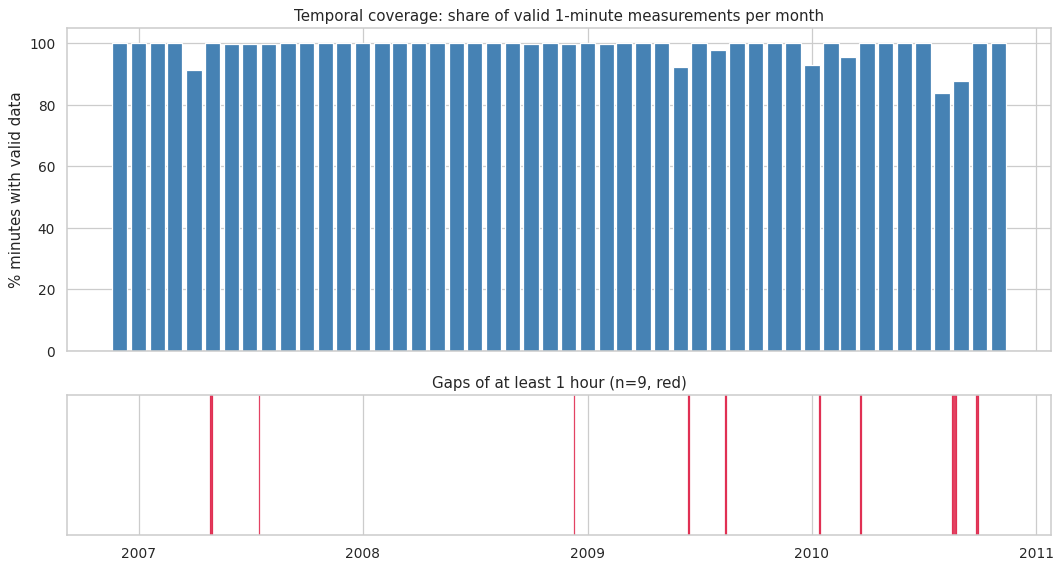

In [ ]:
valid_minutes = minute[TARGET].notna()
overview = pd.Series({
    "Rows (raw file)": RAW_ROWS,
    "Rows after duplicate handling (cleaned)": len(minute),
    "Columns (numeric measurements)": minute.shape[1],
    "Start": minute.index.min(), "End": minute.index.max(),
    "Total span (days)": (minute.index.max() - minute.index.min()).days,
    "Calendar months touched": minute.index.to_period("M").nunique(),
    "Calendar years touched": minute.index.year.nunique(),
    "Unique timestamps": minute.index.nunique(),
    "Nominal sampling frequency": str(ts_info["modal_interval"]),
    "Timestamps missing from the 1-min grid": ts_info["timestamps_missing_from_grid"],
    "Rows with '?' (all 7 measurements missing)": int((~valid_minutes).sum()),
    "Rows with valid measurements": int(valid_minutes.sum()),
    "Duplicate timestamps": dup_ts, "Duplicate full rows": dup_rows,
    "Missing cells (total)": int(minute.isna().sum().sum()),
}, name="value").astype(str).to_frame()
display(overview); save_table(overview, "dataset_overview")

gap_runs = pp.find_runs(~valid_minutes)
monthly_cov = valid_minutes.resample("MS").mean() * 100
fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
ax[0].bar(monthly_cov.index, monthly_cov.values, width=25, color="steelblue")
ax[0].set_ylabel("% minutes with valid data"); ax[0].set_ylim(0, 105)
ax[0].set_title("Temporal coverage: share of valid 1-minute measurements per month")
long_gaps = gap_runs[gap_runs["length"] >= 60]
for _, g in long_gaps.iterrows():
    ax[1].axvspan(g["start"], g["end"], color="crimson", alpha=0.8)
ax[1].set_yticks([]); ax[1].set_title(f"Gaps of at least 1 hour (n={len(long_gaps)}, red)")
ax[1].xaxis.set_major_locator(mdates.YearLocator()); ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout(); save_fig(fig, "01_temporal_coverage"); plt.show()

worst = monthly_cov.sort_values().head(3)

**Interpretation**

The dataset covers 1,441 days over five calendar years at a one-minute interval. Of the 2,075,259 rows, 25,979 (1.25%) contain no measurement, so 2,049,280 rows (98.75%) have valid values. The missing rows form 71 separate runs, 9 of which last at least one hour. Monthly coverage is lowest in August 2010 (83.8% of minutes valid), September 2010 (87.9%) and April 2007 (91.4%); the first and last months are partial calendar months, so their averages should not be compared directly with those of full months. The raw and cleaned row counts are equal, and the missing rows are kept as empty rows so that the regular time grid is preserved.

## 7. Missing-value analysis and preprocessing decisions

Missing values are examined by column, time period, and length of consecutive gaps. The choice of treatment matters because lagged and rolling features depend on the sequence of earlier observations.

| Approach | Benefit | Limitation |
|---|---|---|
| Remove incomplete rows | Does not create replacement values | Can break the regular time sequence |
| Linear interpolation | Can estimate short gaps smoothly | May use later measurements that would not be available when forecasting |
| Limited forward fill | Uses earlier values only | Can carry an outdated reading through a gap |
| Hourly aggregation with a minimum count | Uses the readings actually recorded within each hour | Hours with insufficient readings must be excluded or flagged |

The selected approach is assessed after hourly aggregation. Missing target values are not replaced for model evaluation, and the raw data remains unchanged.


,missing_count,missing_pct
Global_active_power,25979.0,1.251844
Global_reactive_power,25979.0,1.251844
Voltage,25979.0,1.251844
Global_intensity,25979.0,1.251844
Sub_metering_1,25979.0,1.251844
Sub_metering_2,25979.0,1.251844
Sub_metering_3,25979.0,1.251844
ALL_CELLS,181853.0,1.251844


,n_runs,missing_minutes,share_of_missing_%
bucket,,,
1 min,38,38,0.146272
2-5 min,17,38,0.146272
6-15 min,1,6,0.023096
16-60 min,6,206,0.792948
61-240 min,2,153,0.588937
>240 min,7,25538,98.302475


,start,end,length
68,2010-08-17 21:02:00,2010-08-22 21:27:00,7226
69,2010-09-25 03:56:00,2010-09-28 19:12:00,5237
6,2007-04-28 00:21:00,2007-04-30 14:23:00,3723
49,2009-06-13 00:30:00,2009-06-15 07:34:00,3305
58,2010-01-12 14:53:00,2010-01-14 19:01:00,3129
62,2010-03-20 03:52:00,2010-03-21 13:38:00,2027
51,2009-08-13 05:00:00,2009-08-13 19:50:00,891
15,2007-07-15 16:49:00,2007-07-15 18:11:00,83


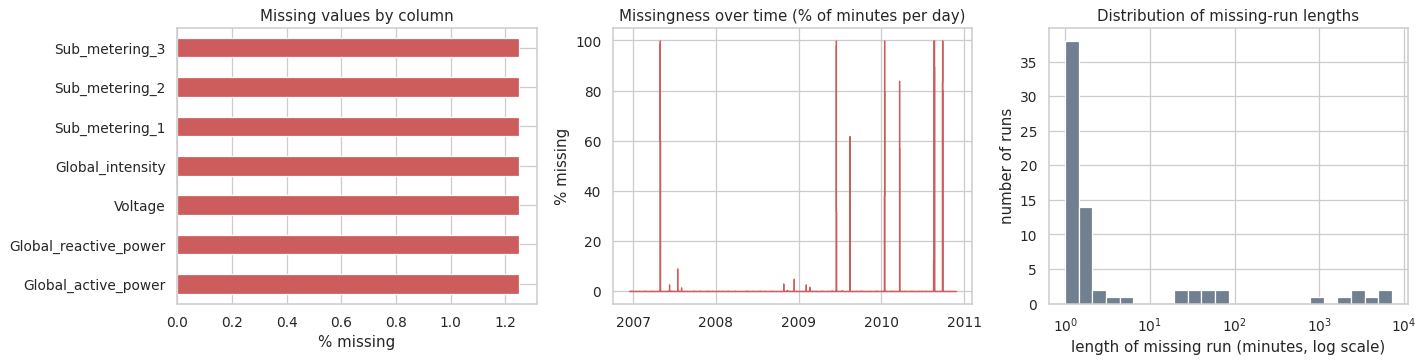

In [ ]:
miss = pp.missing_report(minute)
display(miss); save_table(miss, "missing_value_report")
co_occurrence = (minute.isna().sum(axis=1) > 0).sum(), (minute.isna().all(axis=1)).sum()
identical = bool((minute.isna().sum() == minute.isna().sum().iloc[0]).all() and set(minute.isna().sum(axis=1).unique()) <= {0, minute.shape[1]})

runs = gap_runs.copy()
bins = [0, 1, 5, 15, 60, 240, 100000]; labels = ["1 min", "2-5 min", "6-15 min", "16-60 min", "61-240 min", ">240 min"]
runs["bucket"] = pd.cut(runs["length"], bins=bins, labels=labels)
run_summary = runs.groupby("bucket", observed=False).agg(n_runs=("length", "size"), missing_minutes=("length", "sum"))
run_summary["share_of_missing_%"] = run_summary["missing_minutes"] / run_summary["missing_minutes"].sum() * 100
display(run_summary); save_table(run_summary, "missing_run_length_summary")
display(runs.sort_values("length", ascending=False).head(8)[["start", "end", "length"]])

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
miss.drop("ALL_CELLS")["missing_pct"].plot.barh(ax=ax[0], color="indianred"); ax[0].set_xlabel("% missing"); ax[0].set_title("Missing values by column")
daily_miss = minute[TARGET].isna().resample("D").mean() * 100
ax[1].fill_between(daily_miss.index, daily_miss.values, color="indianred", step="mid"); ax[1].set_title("Missingness over time (% of minutes per day)")
ax[1].set_ylabel("% missing"); ax[1].xaxis.set_major_locator(mdates.YearLocator()); ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax[2].hist(runs["length"], bins=np.logspace(0, np.log10(runs["length"].max() + 1), 25), color="slategray"); ax[2].set_xscale("log")
ax[2].set_xlabel("length of missing run (minutes, log scale)"); ax[2].set_ylabel("number of runs"); ax[2].set_title("Distribution of missing-run lengths")
fig.tight_layout(); save_fig(fig, "02_missing_values"); plt.show()

**Interpretation**

All seven columns have the same 25,979 missing values (1.252%), and every row is either complete or missing in all columns, so no variable can be used to reconstruct another. The 71 missing runs are very uneven in length. Fifty-five last five minutes or less, whereas the 7 runs longer than four hours account for 25,538 of the 25,979 missing minutes (98.3%). The longest run is 7,226 minutes (5.0 days, 17 to 22 August 2010), followed by 5,237 minutes (25 to 28 September 2010) and 3,723 minutes (28 to 30 April 2007). These are the same three months that have the lowest coverage in the previous section. Short dropouts have little effect when minutes are averaged to hours, but multi-day outages cannot be filled credibly, so they are left missing and handled through the hourly validity rule and the row filtering described in Sections 9 and 12.

**Preprocessing rule:** An hour is treated as valid when at least 45 of its 60 minute-level readings are available. For model inputs, gaps of up to three consecutive invalid hours may be filled using the most recent earlier value. Longer gaps remain missing. Hours without an observed target are excluded from supervised model training and evaluation. Section 9 reports the effect of these decisions.


## 8. Descriptive statistics and numerical distributions

The analysis reports the count, mean, standard deviation, quartiles, minimum, maximum, skewness, and kurtosis of the seven numerical measurements. Histograms and boxplots show their distributions and extreme values; the correlation heatmap shows how the variables move together.

High consumption values are not removed simply because they appear as outliers. They may represent genuine periods of heavy electricity use.


,count,mean,std,min,25%,50%,75%,max,skewness,excess_kurtosis
Global_active_power,2049280.0,1.092,1.057,0.076,0.308,0.602,1.528,11.122,1.786,4.219
Global_reactive_power,2049280.0,0.124,0.113,0.000,0.048,0.100,0.194,1.390,1.262,2.606
Voltage,2049280.0,240.840,3.240,223.200,238.990,241.010,242.890,254.150,-0.327,0.725
Global_intensity,2049280.0,4.628,4.444,0.200,1.400,2.600,6.400,48.400,1.849,4.601
Sub_metering_1,2049280.0,1.122,6.153,0.000,0.000,0.000,0.000,88.000,5.945,35.643
Sub_metering_2,2049280.0,1.299,5.822,0.000,0.000,0.000,1.000,80.000,7.091,57.907
Sub_metering_3,2049280.0,6.458,8.437,0.000,0.000,1.000,17.000,31.000,0.725,-1.282


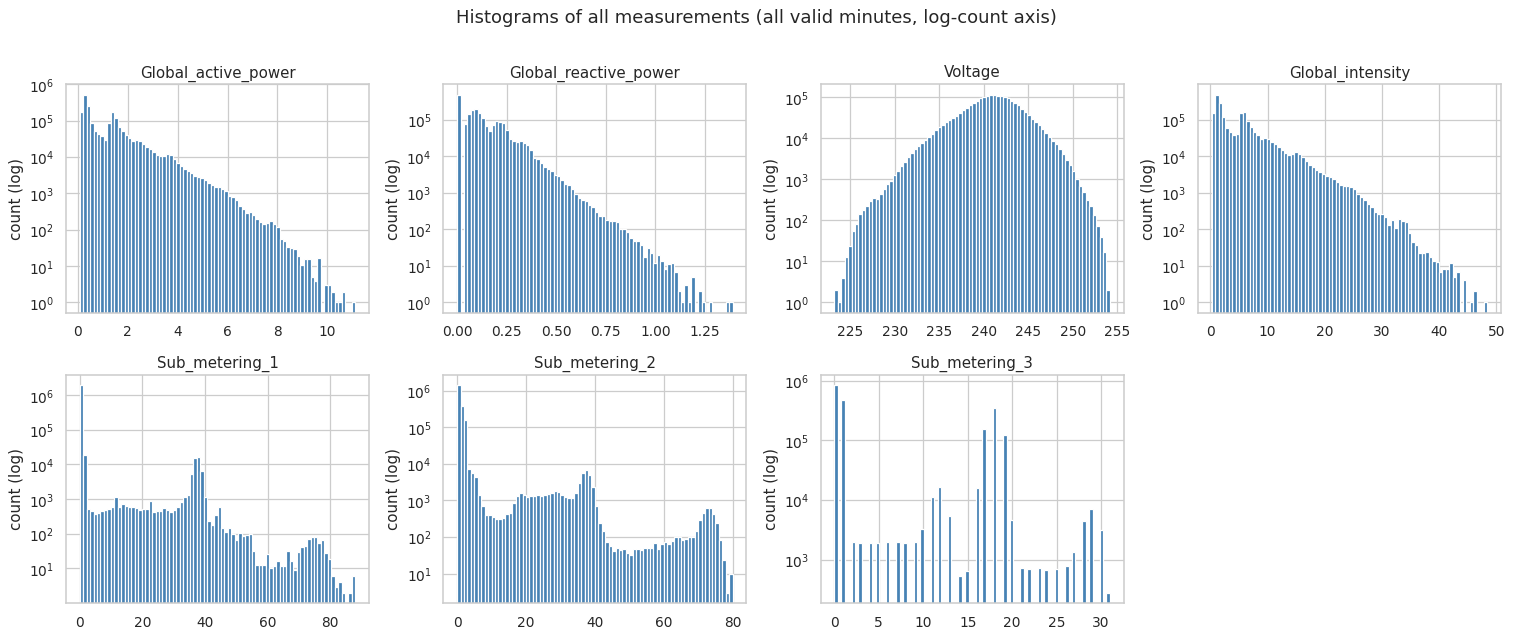

In [ ]:
valid = minute.dropna()
desc = valid.describe().T
desc["skewness"] = valid.skew(); desc["excess_kurtosis"] = valid.kurt()
display(desc.round(3)); save_table(desc.round(4), "descriptive_statistics_minute")

fig, axes = plt.subplots(2, 4, figsize=(17, 7)); axes = axes.ravel()
for a, c in zip(axes, valid.columns):
    a.hist(valid[c], bins=80, color="steelblue"); a.set_title(c); a.set_yscale("log"); a.set_ylabel("count (log)")
axes[-1].axis("off"); fig.suptitle("Histograms of all measurements (all valid minutes, log-count axis)", y=1.01); fig.tight_layout()
save_fig(fig, "03_histograms"); plt.show()

**Interpretation**

The statistics use the 2,049,280 complete minutes. Active power has a mean of 1.092 kW, a median of 0.602 kW, a standard deviation of 1.057 kW and a maximum of 11.122 kW. The mean is well above the median, and the skewness (1.786) and excess kurtosis (4.219) indicate a right-skewed distribution with a long upper tail: most minutes have low demand and a small share have high demand. `Global_intensity` has a similar shape (skewness 1.849). The `Sub_metering_1` and `Sub_metering_2` readings are mostly zero (median 0 Wh, upper quartile 0 and 1 Wh) but reach 88 and 80 Wh, giving skewness of 5.9 and 7.1. `Sub_metering_3` is less sparse (median 1 Wh, upper quartile 17 Wh). `Voltage` is the most symmetric variable (skewness −0.327), with a standard deviation of 3.24 V and values from 223.2 to 254.15 V. Because the high-demand minutes carry large squared errors, RMSE will be more sensitive to them than MAE, and both are reported later.

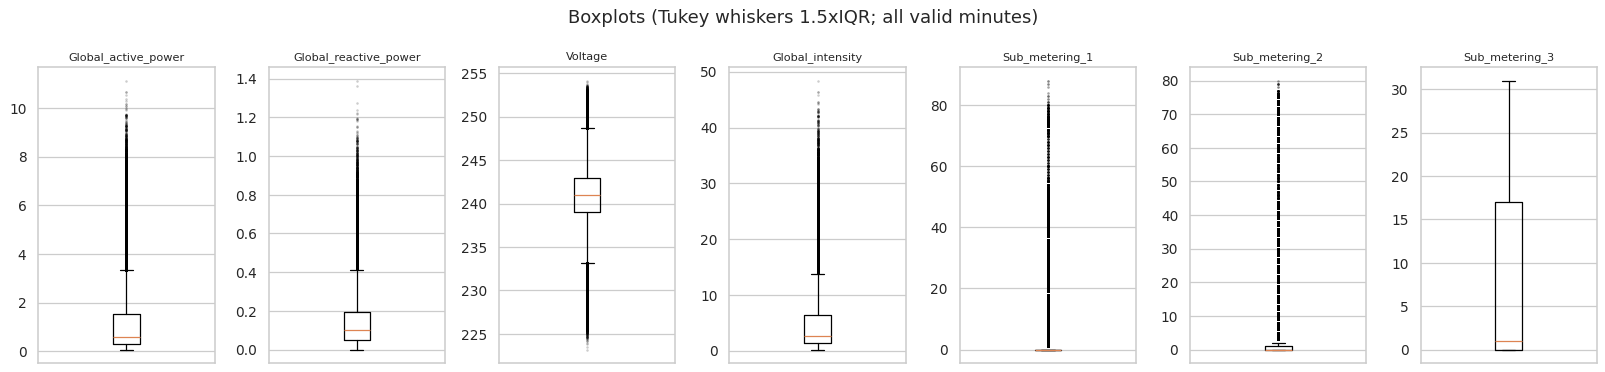

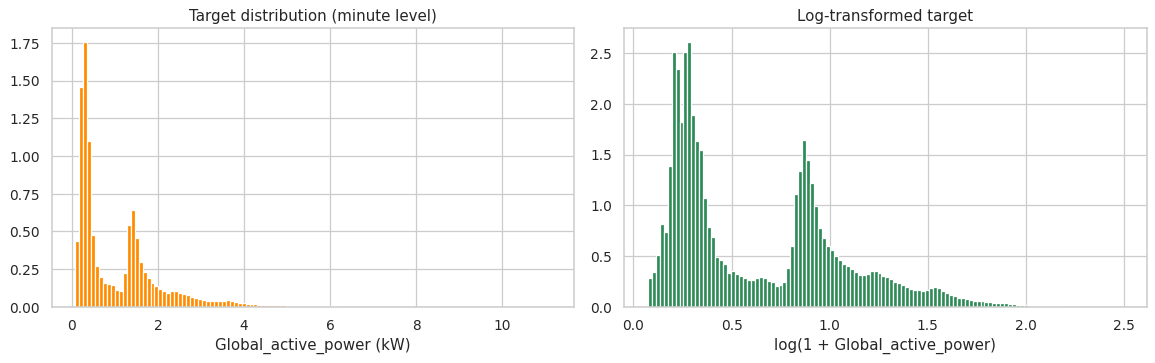

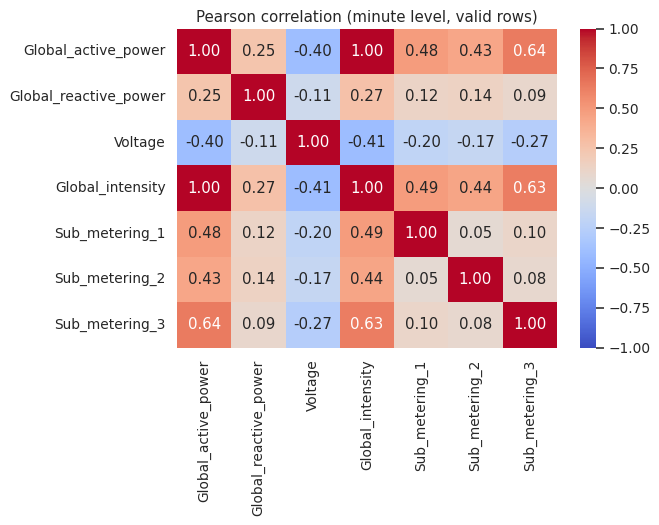

In [ ]:
fig, axes = plt.subplots(1, 7, figsize=(18, 4.2))
for a, c in zip(axes, valid.columns):
    a.boxplot(valid[c].to_numpy(), whis=1.5, flierprops={"markersize": 1, "alpha": 0.2}); a.set_title(c, fontsize=9); a.set_xticks([])
fig.suptitle("Boxplots (Tukey whiskers 1.5xIQR; all valid minutes)"); fig.tight_layout(); save_fig(fig, "04_boxplots"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].hist(valid[TARGET], bins=120, color="darkorange", density=True); ax[0].set_xlabel("Global_active_power (kW)"); ax[0].set_title("Target distribution (minute level)")
ax[1].hist(np.log1p(valid[TARGET]), bins=120, color="seagreen", density=True); ax[1].set_xlabel("log(1 + Global_active_power)"); ax[1].set_title("Log-transformed target")
fig.tight_layout(); save_fig(fig, "05_target_distribution"); plt.show()

corr_min = valid.corr()
fig, ax = plt.subplots(figsize=(7.5, 6)); sns.heatmap(corr_min, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation (minute level, valid rows)"); fig.tight_layout(); save_fig(fig, "06_correlation_heatmap_minute"); plt.show()

g = valid[TARGET]; q1, q3 = g.quantile([.25, .75]); fence = q3 + 1.5 * (q3 - q1)
share_out = (g > fence).mean() * 100
hrs_out = g[g > fence].index.hour.value_counts(normalize=True).sort_index()
top_hours = hrs_out.sort_values(ascending=False).head(3)

**Interpretation**

*Outliers.* By the Tukey rule, 4.63% of valid minutes exceed the upper fence of 3.36 kW for active power. These observations are concentrated in the evening: 20:00 contains 12% of them, 21:00 contains 11% and 19:00 contains 11%. No negative or otherwise impossible values were found, and voltage stays between 223 and 254 V, so the high values are consistent with genuine appliance use and not with recording errors. They were retained.

*Target distribution.* The skewness of active power is 1.79 on the original scale and 0.74 after a log(1 + x) transformation. The transformation reduces the asymmetry but does not remove it, and the original kW scale is kept so that errors stay interpretable.

*Correlations at minute level.* Active power is almost perfectly correlated with `Global_intensity` (r = 0.999). Its other correlations are moderate: `Sub_metering_3` 0.64, `Sub_metering_1` 0.48, `Sub_metering_2` 0.43, `Global_reactive_power` 0.25 and `Voltage` −0.40. The three sub-metering variables are only weakly correlated with one another (0.05 to 0.10). The high value for `Global_intensity` is expected because both variables describe the same electrical load. The other coefficients describe association only and do not show cause and effect.

## 9. Temporal aggregation and modeling dataset

The minute-level readings are grouped into hourly observations. The aggregation depends on the measurement: power, voltage, and current are averaged, while the sub-metering readings are converted into estimated hourly energy totals.

| Variable | Hourly calculation | Resulting measure |
|---|---|---|
| `Global_active_power` | Mean of available minute readings | Average active power (kW) |
| `Global_reactive_power` | Mean | Average reactive power |
| `Voltage` | Mean | Average voltage (V) |
| `Global_intensity` | Mean | Average current (A) |
| `Sub_metering_1/2/3` | Mean minute-level energy × 60 | Estimated hourly energy (Wh) |
| `Other_energy_Wh` | Active-power-based hourly energy minus the three sub-meter totals | Estimated energy outside the three sub-meters (Wh) |

An hour must contain at least 45 valid minute readings to be retained. For hours with 45–59 valid readings, averages are based on the available measurements. Hours below the threshold are marked invalid. Scaling incomplete-hour sub-meter readings assumes the observed minutes represent the missing minutes; this is a limitation of the estimate.


In [ ]:
hourly = pp.aggregate_to_hourly(minute, min_obs=MIN_OBS_PER_HOUR)
pp.validate_chronological(hourly.index)
value_cols = [c for c in hourly.columns if c not in ("n_obs", "is_valid_hour")]
interval_counts = hourly.index.to_series().diff().value_counts().rename("count").to_frame()
n_hours = len(hourly); n_valid = int(hourly["is_valid_hour"].sum())
partial_valid = int(((hourly["n_obs"] >= MIN_OBS_PER_HOUR) & (hourly["n_obs"] < 60)).sum())
invalid_runs = pp.find_runs(~hourly["is_valid_hour"])
display(interval_counts.rename_axis("interval")); display(hourly.head(3)); display(hourly.tail(3))
agg_summary = pd.Series({"Hourly intervals": n_hours, "Start": hourly.index.min(), "End": hourly.index.max(),
    "Valid hours (>= %d observed minutes)" % MIN_OBS_PER_HOUR: n_valid, "Invalid hours (set to NaN)": n_hours - n_valid,
    "  of which with 0 observed minutes": int((hourly["n_obs"] == 0).sum()),
    "  of which partially observed (1-%d min)" % (MIN_OBS_PER_HOUR - 1): int(((hourly["n_obs"] > 0) & (hourly["n_obs"] < MIN_OBS_PER_HOUR)).sum()),
    "Valid hours with 45-59 observed minutes": partial_valid, "Runs of consecutive invalid hours": len(invalid_runs),
    "Longest invalid run (hours)": int(invalid_runs["length"].max())}, name="value").astype(str).to_frame()
display(agg_summary); save_table(agg_summary, "hourly_aggregation_summary")
display(invalid_runs.sort_values("length", ascending=False).head(6))

,count
interval,
0 days 01:00:00,34588


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Other_energy_Wh,n_obs,is_valid_hour
timestamp,,,,,,,,,,
2006-12-16 17:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36,False
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,403.0,1012.0,2217.200000,60,True
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,86.0,1001.0,2313.233333,60,True


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Other_energy_Wh,n_obs,is_valid_hour
timestamp,,,,,,,,,,
2010-11-26 19:00:00,1.659333,0.060033,236.741,7.056667,0.0,4.0,0.0,1655.333333,60,True
2010-11-26 20:00:00,1.163700,0.061167,239.396,4.913333,0.0,64.0,0.0,1099.700000,60,True
2010-11-26 21:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,False


,value
Hourly intervals,34589
Start,2006-12-16 17:00:00
End,2010-11-26 21:00:00
Valid hours (>= 45 observed minutes),34151
Invalid hours (set to NaN),438
of which with 0 observed minutes,421
of which partially observed (1-44 min),17
Valid hours with 45-59 observed minutes,66
Runs of consecutive invalid hours,16
Longest invalid run (hours),121


,start,end,length
13,2010-08-17 21:00:00,2010-08-22 21:00:00,121
14,2010-09-25 04:00:00,2010-09-28 18:00:00,87
1,2007-04-28 00:00:00,2007-04-30 14:00:00,63
9,2009-06-13 00:00:00,2009-06-15 07:00:00,56
11,2010-01-12 15:00:00,2010-01-14 18:00:00,52
12,2010-03-20 04:00:00,2010-03-21 13:00:00,34


**Preprocessing outcome**

The minute data were aggregated to 34,589 hourly rows, from 16 December 2006 17:00 to 26 November 2010 21:00, and every interval is exactly one hour (34,588 intervals). Of these hours, 34,151 meet the rule of at least 45 observed minutes and 438 do not: 421 have no observed minutes and 17 have between 1 and 44. A further 66 valid hours have 45 to 59 observed minutes, so their means are based on the available minutes only. The first and last hours are partial because the record starts at 17:24 and ends at 21:02 (36 and 3 observed minutes), so both are invalid. The 438 invalid hours form 16 runs. The longest is 121 hours (17 to 22 August 2010), followed by 87 hours (25 to 28 September 2010) and 63 hours (28 to 30 April 2007). Invalid hours are set to missing and are not estimated at this stage. The 45-minute threshold is a judgement, and the notebook does not test other thresholds, so its effect on forecast accuracy is unknown.

### 9.3 Short gaps and the recovery experiment

For model inputs, up to three consecutive invalid hours may be filled with the last available earlier reading. Filled values are flagged so they can be distinguished from observed measurements. Longer gaps remain missing, and missing target values are not filled for evaluation.

To assess this choice, the code temporarily masks known observations in one- to three-hour blocks and measures how accurately different methods recover them. Linear interpolation is shown for comparison only: it uses a later observation and is therefore unsuitable as a real-time forecasting input.


In [ ]:
filled, impute_flags = pp.causal_fill(hourly, value_cols, FILL_LIMIT_HOURS)
n_imputed_target = int(impute_flags[TARGET].sum()); n_still_missing = int(filled[TARGET].isna().sum())
imp_res = pp.imputation_experiment(hourly[TARGET], gap_lengths=(1, 2, 3), n_gaps=300, seed=SEED)
imp_pivot = imp_res.pivot(index="method", columns="gap_length_h", values="MAE").round(3)
display(imp_pivot.rename_axis(columns="MAE (kW) by gap length (h)")); save_table(imp_res.round(4), "imputation_recovery_experiment", index=False)
display(pd.Series({"Target hours imputed (causal ffill, limit %dh)" % FILL_LIMIT_HOURS: n_imputed_target,
                   "Target hours still missing after fill": n_still_missing,
                   "Share of all hours imputed": f"{n_imputed_target/n_hours*100:.3f}%"}, name="value").to_frame())
best_by_len = imp_res.loc[imp_res.groupby("gap_length_h")["MAE"].idxmin(), ["gap_length_h", "method", "MAE"]]

MAE (kW) by gap length (h),1,2,3
method,,,
ffill (causal),0.439,0.523,0.640
linear interpolation (uses future),0.341,0.386,0.479
same hour yesterday (causal),0.599,0.640,0.626


,value
"Target hours imputed (causal ffill, limit 3h)",30
Target hours still missing after fill,408
Share of all hours imputed,0.087%


**Interpretation**

Causal forward fill can bridge only 30 target hours (0.087% of all hours). The other 408 invalid hours stay missing because their gaps are longer than 3 hours. In the recovery experiment, known hours were masked in blocks of 1, 2 and 3 hours (300 blocks per length). Linear interpolation had the lowest MAE at every gap length (0.341, 0.386 and 0.479 kW), compared with 0.439, 0.523 and 0.640 kW for forward fill. Interpolation uses the observation after the gap, which would not be available when forecasting, so it is shown only for comparison. Among methods that use past values only, forward fill had the lower MAE for 1-hour and 2-hour gaps, while the value from the same hour on the previous day was marginally lower for 3-hour gaps (0.626 against 0.640 kW). Forward-fill errors of 0.44 to 0.64 kW are large relative to the hourly standard deviation of 0.90 kW, so filled inputs are rough placeholders. Their use is acceptable only because few hours are affected, and target values are never filled.

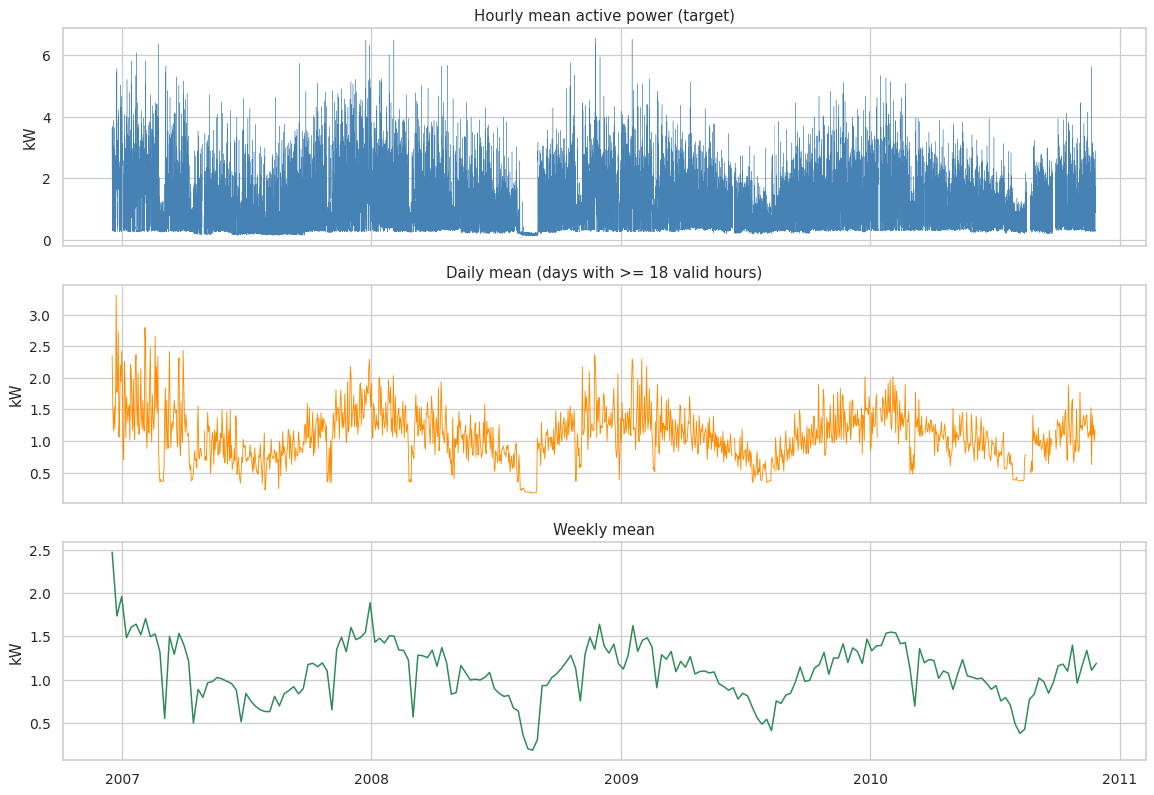

In [ ]:
# aggregated series plots: hourly, daily and weekly views
daily = hourly[TARGET].resample("D").agg(["mean", "count"]); daily.loc[daily["count"] < 18, "mean"] = np.nan   # >=18 valid hours
weekly = hourly[TARGET].resample("W").mean()
fig, ax = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
ax[0].plot(hourly.index, hourly[TARGET], lw=0.3, color="steelblue"); ax[0].set_title("Hourly mean active power (target)")
ax[1].plot(daily.index, daily["mean"], lw=0.7, color="darkorange"); ax[1].set_title("Daily mean (days with >= 18 valid hours)")
ax[2].plot(weekly.index, weekly.values, lw=1.2, color="seagreen"); ax[2].set_title("Weekly mean")
for a in ax: a.set_ylabel("kW")
ax[2].xaxis.set_major_locator(mdates.YearLocator()); ax[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout(); save_fig(fig, "07_target_hourly_daily_weekly"); plt.show()

**Interpretation**

Aggregation reduced 2,075,259 minute rows to 34,589 hourly rows. Hourly average active power ranges from 0.12 to 6.56 kW (standard deviation 0.90 kW), whereas the minute-level maximum is 11.12 kW. Short peaks are averaged out, so the models forecast hourly average load and not instantaneous peaks. The daily and weekly series smooth the hourly variation so that changes over weeks and months are easier to see; they are analysed quantitatively in Section 10. Days with fewer than 18 valid hours are left blank in the daily series, which is why the line breaks at the long outages.

In [ ]:
# 9.5 preprocessing decision table (all evidence is computed)
decision = pd.DataFrame([
 ["Text file with '?' tokens", f"{int((token_audit['missing_token']+token_audit['empty']).iloc[0]):,} '?'/empty fields per column; {int(token_audit['unexpected_nonnumeric'].sum())} other bad tokens", "Read '?' and empty fields as NaN; columns -> float64",
  "'?' is the documented missing marker (the last column is simply left empty); zero would be a false measurement", "Cause of missingness is undocumented"],
 ["Timestamps", f"{n_invalid_ts} invalid; {ts_info['timestamps_missing_from_grid']} absent from 1-min grid; sorted in file: {raw_was_sorted}", "Parse day-first; sort; assert strictly increasing",
  "Lags / rolling windows / splits require a correct ordered axis", "Local time; any DST effects are not documented"],
 ["Duplicates", f"{dup_ts} duplicate timestamps, {dup_rows} duplicate rows", "Policy: drop identical rows, average conflicting timestamps (none occurred)", "Avoid double counting without discarding conflicting info silently", "Policy untested on real duplicates (unit-tested on synthetic data)"],
 ["Missing minutes", f"{len(minute)-int(valid_minutes.sum()):,} rows ({(~valid_minutes).mean()*100:.2f}%), {len(runs)} runs, longest {int(runs['length'].max()):,} min", "Keep NaN rows; no minute-level imputation", "Preserves the regular grid; long outages cannot be reconstructed credibly", "Missing periods are not representative of usage"],
 ["Incomplete hours", f"{n_hours-n_valid:,} hours with < {MIN_OBS_PER_HOUR} observed minutes; {partial_valid} valid hours with 45-59 min", f"Hourly mean of observed minutes; hour valid only if >= {MIN_OBS_PER_HOUR} min", "Isolated missing minutes lose almost no information; mostly-empty hours would be unreliable", "Threshold of 45 is a judgement call"],
 ["Short invalid-hour gaps", f"{n_imputed_target} target hours bridgeable (<= {FILL_LIMIT_HOURS} h)", f"Causal forward fill (<= {FILL_LIMIT_HOURS} h) for INPUTS only, flagged", "Uses past only (no leakage); recovery experiment shows modest error", "Flat fill underestimates variability; flagged values are few"],
 ["Long invalid-hour gaps", f"longest {int(invalid_runs['length'].max())} h; {n_still_missing:,} hours remain NaN", "Not imputed; rows with missing target or inputs excluded from supervised data", "Interpolating days of data would invent a consumption pattern", "Fewer rows; lags after a gap are unavailable"],
 ["Evaluated targets", "validation/test targets must reflect reality", "Targets are never imputed", "Prevents optimistic evaluation / leakage", "Evaluation covers observed hours only"],
 ["Extreme values", f"{share_out:.2f}% of minutes above the Tukey fence", "Retained", "Plausible appliance peaks (within physical limits), not errors", "Large errors dominate RMSE"],
], columns=["Issue", "Evidence", "Chosen action", "Justification", "Potential limitation"])
display(decision); save_table(decision, "preprocessing_decision_table", index=False)

hourly.to_csv(PROCESSED_DIR / "hourly_observed.csv")
filled_out = filled.copy(); filled_out["target_imputed"] = impute_flags[TARGET]
filled_out.to_csv(PROCESSED_DIR / "hourly_inputs_causal_filled.csv")
print("Saved processed datasets:", [p.name for p in PROCESSED_DIR.glob("*.csv")])

,Issue,Evidence,Chosen action,Justification,Potential limitation
0,Text file with '?' tokens,"25,979 '?'/empty fields per column; 0 other bad tokens",Read '?' and empty fields as NaN; columns -> float64,'?' is the documented missing marker (the last column is simply left empty); zero would be a false measurement,Cause of missingness is undocumented
1,Timestamps,0 invalid; 0 absent from 1-min grid; sorted in file: True,Parse day-first; sort; assert strictly increasing,Lags / rolling windows / splits require a correct ordered axis,Local time; any DST effects are not documented
2,Duplicates,"0 duplicate timestamps, 0 duplicate rows","Policy: drop identical rows, average conflicting timestamps (none occurred)",Avoid double counting without discarding conflicting info silently,Policy untested on real duplicates (unit-tested on synthetic data)
3,Missing minutes,"25,979 rows (1.25%), 71 runs, longest 7,226 min",Keep NaN rows; no minute-level imputation,Preserves the regular grid; long outages cannot be reconstructed credibly,Missing periods are not representative of usage
4,Incomplete hours,438 hours with < 45 observed minutes; 66 valid hours with 45-59 min,Hourly mean of observed minutes; hour valid only if >= 45 min,Isolated missing minutes lose almost no information; mostly-empty hours would be unreliable,Threshold of 45 is a judgement call
5,Short invalid-hour gaps,30 target hours bridgeable (<= 3 h),"Causal forward fill (<= 3 h) for INPUTS only, flagged",Uses past only (no leakage); recovery experiment shows modest error,Flat fill underestimates variability; flagged values are few
6,Long invalid-hour gaps,longest 121 h; 408 hours remain NaN,Not imputed; rows with missing target or inputs excluded from supervised data,Interpolating days of data would invent a consumption pattern,Fewer rows; lags after a gap are unavailable
7,Evaluated targets,validation/test targets must reflect reality,Targets are never imputed,Prevents optimistic evaluation / leakage,Evaluation covers observed hours only
8,Extreme values,4.63% of minutes above the Tukey fence,Retained,"Plausible appliance peaks (within physical limits), not errors",Large errors dominate RMSE


Saved processed datasets: ['hourly_observed.csv', 'hourly_inputs_causal_filled.csv']


**Preprocessing outcome**

The decision table links each finding to the action taken and its limitation. The data showed no invalid or duplicate timestamps and no non-numeric entries, so the only quality problem is missing measurements (1.25% of minutes, concentrated in a few long outages). The treatment keeps the raw data unchanged and keeps missing minutes as empty rows. It averages minutes to hours with a 45-minute validity rule (438 of 34,589 hours invalid) and forward-fills at most 3 hours of model inputs (30 target hours affected). Target values used for evaluation are never filled, and extreme values (4.63% of minutes above the Tukey fence) are retained. These choices preserve the time order and avoid using future information. The notebook does not test whether they improve forecast accuracy, so no such claim is made. Hours that remain missing reduce the number of supervised rows in Section 12. The processed hourly files were saved to `data/processed/`.

## 10. Time-series patterns and exploratory analysis

The hourly series is examined at several time scales. The plots show changes across the full observation period, a 30-day rolling average, and differences by hour, weekday, and month. These views help identify recurring patterns that may be useful when constructing forecasting features.


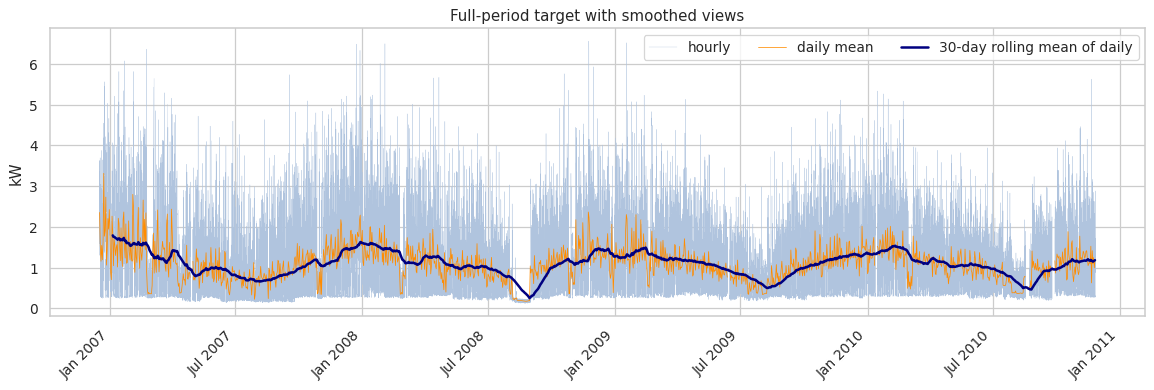

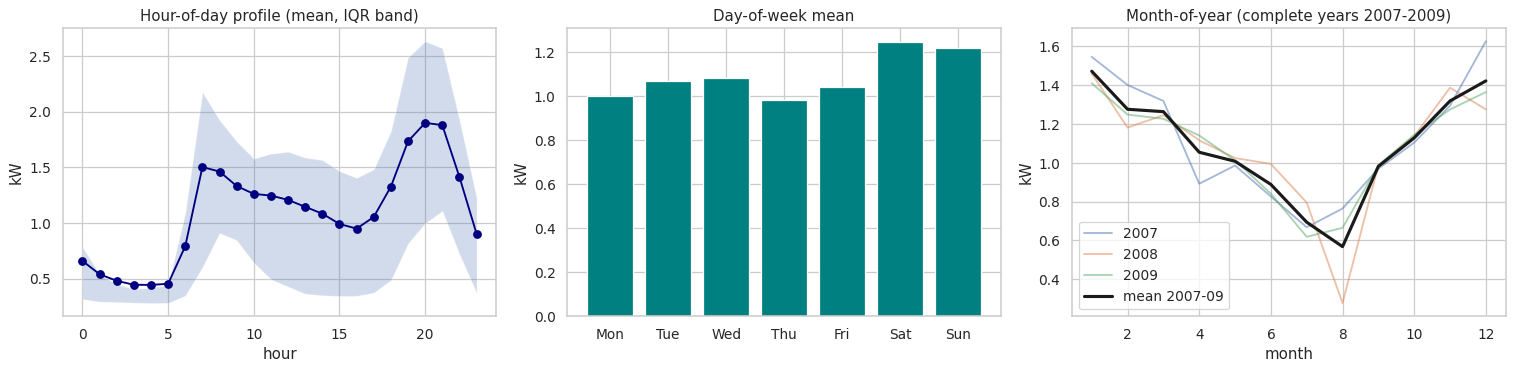

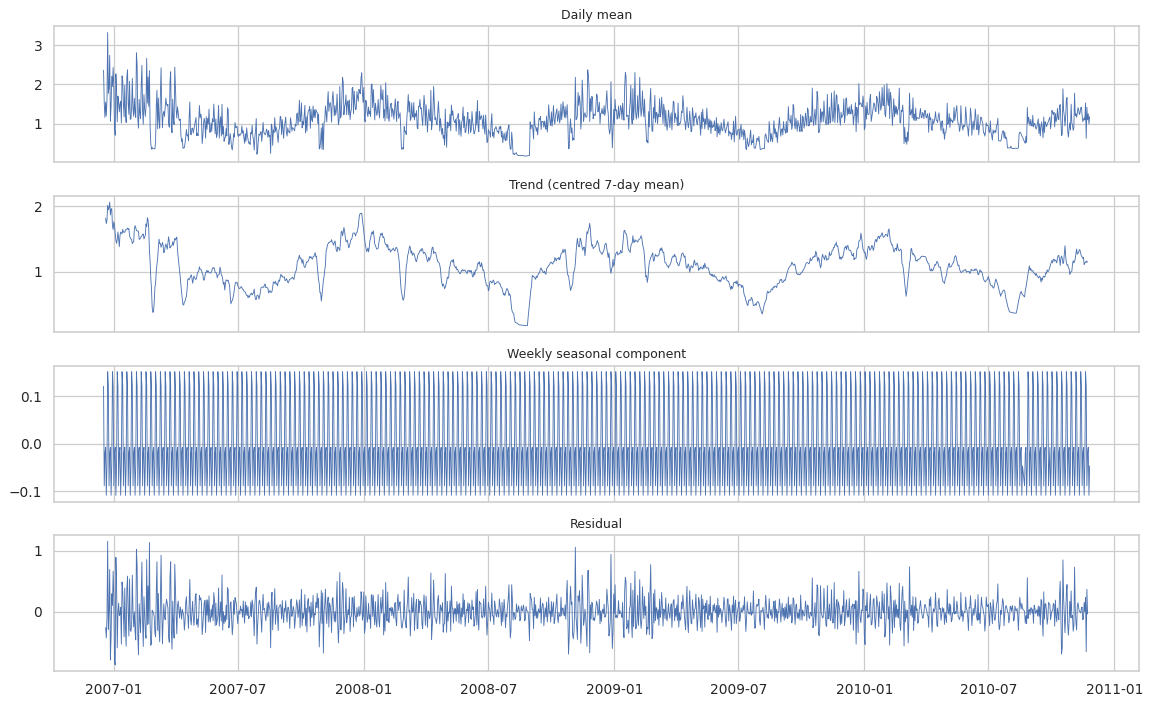

In [ ]:
y_h = hourly[TARGET]
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(y_h.index, y_h, lw=0.25, color="lightsteelblue", label="hourly")
ax.plot(daily.index, daily["mean"], lw=0.6, color="darkorange", label="daily mean")
ax.plot(daily.index, daily["mean"].rolling(30, min_periods=20).mean(), lw=2, color="navy", label="30-day rolling mean of daily")
ax.set_ylabel("kW"); ax.set_title("Full-period target with smoothed views"); ax.legend(ncol=3)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y")); plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
fig.tight_layout(); save_fig(fig, "08_full_series_smoothed"); plt.show()

hv = y_h.dropna().to_frame("y"); hv["hour"] = hv.index.hour; hv["dow"] = hv.index.dayofweek; hv["month"] = hv.index.month; hv["year"] = hv.index.year
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
g = hv.groupby("hour")["y"]; ax[0].plot(g.mean(), marker="o", color="navy"); ax[0].fill_between(g.mean().index, g.quantile(.25), g.quantile(.75), alpha=.25); ax[0].set_title("Hour-of-day profile (mean, IQR band)"); ax[0].set_xlabel("hour")
dn = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]; ax[1].bar(dn, hv.groupby("dow")["y"].mean(), color="teal"); ax[1].set_title("Day-of-week mean")
for yr, grp in hv[hv.year.between(2007, 2009)].groupby("year"): ax[2].plot(grp.groupby("month")["y"].mean(), alpha=.5, label=str(yr))
ax[2].plot(hv[hv.year.between(2007, 2009)].groupby("month")["y"].mean(), color="k", lw=2.5, label="mean 2007-09"); ax[2].set_title("Month-of-year (complete years 2007-2009)"); ax[2].set_xlabel("month"); ax[2].legend()
for a in ax: a.set_ylabel("kW")
fig.tight_layout(); save_fig(fig, "09_hour_dow_month_profiles"); plt.show()

# classical additive decomposition (period 7) of the daily series, linearly interpolating <=3 missing days only for this descriptive plot
d = daily["mean"].interpolate(limit=3, limit_area="inside").dropna()
trend = d.rolling(7, center=True).mean(); detr = d - trend
seas = detr.groupby(d.index.dayofweek).transform("mean"); resid = d - trend - seas
fs = max(0, 1 - resid.var() / (resid + seas).dropna().var()); ft = max(0, 1 - resid.var() / (resid + trend).dropna().var())
fig, ax = plt.subplots(4, 1, figsize=(13, 8), sharex=True)
for a, s, t in zip(ax, [d, trend, seas, resid], ["Daily mean", "Trend (centred 7-day mean)", "Weekly seasonal component", "Residual"]):
    a.plot(s.index, s, lw=0.7); a.set_title(t, fontsize=10)
fig.tight_layout(); save_fig(fig, "10_weekly_decomposition"); plt.show()

yc_corr = hv[hv.year.between(2007, 2009)].groupby(["year", "month"])["y"].mean().unstack(0).corr().to_numpy().min()
hp = hv.groupby("hour")["y"].mean(); mp = hv[hv.year.between(2007, 2009)].groupby("month")["y"].mean(); yr = hv[hv.year.between(2007, 2010)].groupby("year")["y"].mean()
roll30 = daily["mean"].rolling(30, min_periods=20).mean()

**Interpretation**

*Daily pattern.* Mean active power is lowest at 04:00 (0.44 kW) and highest at 20:00 (1.90 kW), a ratio of 4.3. Hour of day alone accounts for 23.5% of the variance of the hourly values.

*Weekly pattern.* Day-of-week means lie between 0.98 kW (Thursday) and 1.25 kW (Saturday), and weekday alone accounts for 1.1% of the variance. The seasonal strength of the weekly component in the daily series is 0.13 on a scale from 0 to 1, so the weekly cycle is weak compared with the daily one.

*Annual pattern.* In the complete years 2007 to 2009 the monthly mean is highest in January (1.47 kW) and lowest in August (0.57 kW), a ratio of 2.59. The three yearly curves are positively correlated (lowest pairwise r = 0.77). This suggests a recurring annual pattern, but with about four years of data a stable seasonal cycle cannot be established.

*Level over time.* Yearly means are 1.12 kW (2007), 1.07 kW (2008), 1.08 kW (2009) and 1.06 kW (2010, which ends in November). The 30-day rolling mean varies between 0.25 and 1.79 kW, so changes from month to month are larger than the differences between years.

*Variability.* The standard deviation is 0.90 kW for hourly values and 0.42 kW for daily means, so much of the variation occurs within days. The lowest daily mean is 0.17 kW (25 August 2008) and the highest is 3.31 kW (23 December 2006). The decomposition residual has a standard deviation of 0.24 kW, so substantial day-to-day variation remains after the 7-day trend and weekly component are removed.

## 11. Analytical questions

Six questions examine the consumption series from different perspectives. Each question includes its method, visual evidence, calculated results, and an interpretation. Questions 4 and 5 focus on lagged values and moving averages, as required by the assignment. Question 6 compares their forecasting performance using historical information only.


In [ ]:
qrows = []   # collects key quantitative results of every question -> outputs/tables/analytical_question_results.csv
def record(q, metric, value): qrows.append({"question": q, "metric": metric, "value": value})
explore_end = hourly.index[int(len(hourly) * EXPLORATION_FRAC)]
y_explore = y_h[y_h.index < explore_end]
print(f"Exploration window for Q4-Q6: {y_explore.index.min()} -> {y_explore.index.max()} ({y_explore.notna().sum():,} observed hours)")

Exploration window for Q4-Q6: 2006-12-16 17:00:00 -> 2010-02-11 15:00:00 (27,476 observed hours)


**Interpretation**

Questions 4 to 6 use the first 80% of the hourly series: 16 December 2006 17:00 to 11 February 2010 15:00, with 27,476 observed hours. The window ends before the test period begins (13 April 2010), so the test data are not used in these exploratory analyses. It does extend past the end of the training period (2 September 2009) into the validation period, so validation data were available when the lag and moving-average features were chosen. The test data were not.

### Q1. Is household electricity consumption increasing or decreasing over time?

Monthly average active power is used to examine the longer-term direction of the series. Months with less than 90% valid hourly coverage are excluded. The analysis estimates the change in kW per year, checks the rank association with time, and compares corresponding months across years to distinguish a longer-term change from seasonal differences.

Because monthly observations are related over time and the dataset spans only a few years, the trend estimates should not be treated as proof of a permanent change in household demand.


year,2007,2008,2009,2010
month,,,,
1,1.546,1.460,1.410,1.431
2,1.401,1.181,1.248,1.376
3,1.319,1.245,1.227,1.130
4,0.892,1.116,1.141,1.027
5,0.986,1.024,1.013,1.095
6,0.826,0.994,0.840,0.970
7,0.667,0.795,0.618,0.721
8,0.764,0.277,0.664,NaN
9,0.969,0.988,0.987,NaN


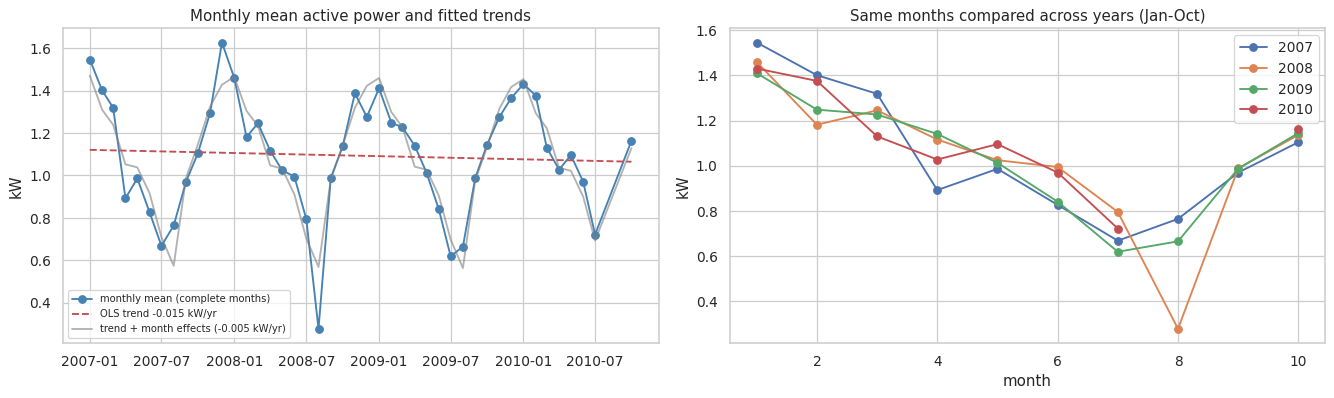

In [ ]:
mon = y_h.resample("MS").agg(["mean", "count"]); mon["expected"] = mon.index.days_in_month * 24
mon = mon[mon["count"] >= 0.9 * mon["expected"]].copy()
t_years = (mon.index - mon.index[0]).days.to_numpy() / 365.25
lr = stats.linregress(t_years, mon["mean"].to_numpy()); rho, p_rho = stats.spearmanr(t_years, mon["mean"])
D = np.column_stack([t_years, pd.get_dummies(mon.index.month).to_numpy(float)])       # trend + 12 month dummies (no separate intercept)
beta, *_ = np.linalg.lstsq(D, mon["mean"].to_numpy(), rcond=None); slope_adj = beta[0]
common = mon[mon.index.month <= 10].assign(year=lambda d: d.index.year, month=lambda d: d.index.month)
yoy = common.pivot(index="month", columns="year", values="mean")
yoy_means = yoy.dropna().mean()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
ax[0].plot(mon.index, mon["mean"], "o-", color="steelblue", label="monthly mean (complete months)")
ax[0].plot(mon.index, lr.intercept + lr.slope * t_years, "r--", label=f"OLS trend {lr.slope:+.3f} kW/yr")
ax[0].plot(mon.index, D @ beta, color="gray", alpha=.6, label=f"trend + month effects ({slope_adj:+.3f} kW/yr)")
ax[0].set_ylabel("kW"); ax[0].set_title("Monthly mean active power and fitted trends"); ax[0].legend(fontsize=8)
for yr_ in yoy.columns: ax[1].plot(yoy.index, yoy[yr_], marker="o", label=str(yr_))
ax[1].set_xlabel("month"); ax[1].set_ylabel("kW"); ax[1].set_title("Same months compared across years (Jan-Oct)"); ax[1].legend()
fig.tight_layout(); save_fig(fig, "11_Q1_trend"); plt.show()
display(yoy.round(3))
for k, v in {"ols_slope_kW_per_year": lr.slope, "ols_p_value": lr.pvalue, "spearman_rho": rho, "seasonally_adjusted_slope_kW_per_year": slope_adj}.items(): record("Q1", k, v)
direction = ("decreasing" if lr.slope < 0 else "increasing") + (" but NOT statistically distinguishable from zero" if lr.pvalue > 0.05 else " and statistically significant")

**Interpretation**

Over the 44 months with at least 90% valid hours, monthly mean active power changes by −0.015 kW per year in the OLS fit. The fit explains almost none of the variation (R² = 0.00), and the slope is not statistically distinguishable from zero (p = 0.708; Spearman ρ = −0.05). When month-of-year effects are included, the slope is −0.005 kW per year, about −0.5% of the overall mean of 1.09 kW. Comparing the same months across years gives similar levels. For the months available in all four years (January to July and October), mean consumption is 1.093 kW in 2007, 1.119 kW in 2008, 1.080 kW in 2009 and 1.114 kW in 2010. Individual months move in different directions: January falls from 1.546 kW in 2007 to 1.431 kW in 2010, while April rises from 0.892 to 1.027 kW.

Consumption therefore shows no clear long-term increase or decrease. The fitted drift over the whole record is about 0.02 kW, whereas monthly means range from 0.28 to 1.63 kW, so seasonal variation is much larger than any trend. The lowest monthly mean (August 2008, 0.277 kW) is far below August 2007 (0.764 kW) and August 2009 (0.664 kW); the data do not record why. Four years is too short to separate a change in household efficiency from a change in occupancy, and the p-value assumes independent observations although monthly means are autocorrelated. For forecasting, a slow trend does not appear to be a major feature, and the recent level can be represented by lag and rolling-mean features.

### Q2. How does electricity use differ by hour and day of the week?

Average active power is compared across the 24 hours of the day and seven days of the week. The heatmap shows the combined pattern, while the weekday and weekend profiles make differences easier to compare. The analysis also calculates how much of the observed variation is associated with these time groupings.


,weekday,weekend,weekend/weekday
night 00-05,0.457,0.623,1.364
morning 06-09,1.384,0.985,0.711
daytime 10-16,1.008,1.427,1.416
evening 17-22,1.451,1.803,1.243


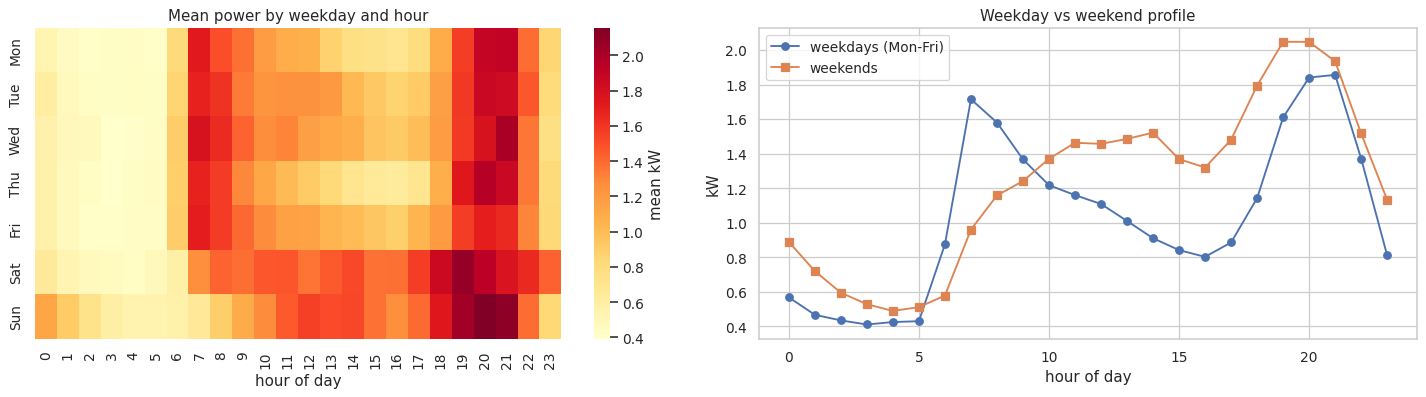

In [ ]:
hw = hv.copy(); hw["weekend"] = hw["dow"] >= 5
heat = hw.pivot_table(index="dow", columns="hour", values="y", aggfunc="mean"); heat.index = dn
prof = hw.groupby(["weekend", "hour"])["y"].mean().unstack(0); prof.columns = ["weekday", "weekend"]
periods = {"night 00-05": range(0, 6), "morning 06-09": range(6, 10), "daytime 10-16": range(10, 17), "evening 17-22": range(17, 23)}
ptab = pd.DataFrame({k: [prof.loc[list(v), "weekday"].mean(), prof.loc[list(v), "weekend"].mean()] for k, v in periods.items()}, index=["weekday", "weekend"]).T
ptab["weekend/weekday"] = ptab["weekend"] / ptab["weekday"]
eta = lambda keys: hw.groupby(keys)["y"].transform("mean").var() / hw["y"].var()
fig, ax = plt.subplots(1, 2, figsize=(16, 4.6))
sns.heatmap(heat, cmap="YlOrRd", ax=ax[0], cbar_kws={"label": "mean kW"}); ax[0].set_title("Mean power by weekday and hour"); ax[0].set_xlabel("hour of day")
ax[1].plot(prof["weekday"], "o-", label="weekdays (Mon-Fri)"); ax[1].plot(prof["weekend"], "s-", label="weekends"); ax[1].set_xlabel("hour of day"); ax[1].set_ylabel("kW"); ax[1].legend(); ax[1].set_title("Weekday vs weekend profile")
fig.tight_layout(); save_fig(fig, "12_Q2_hour_weekday_heatmap"); plt.show()
display(ptab.round(3)); save_table(ptab.round(4), "Q2_period_comparison")
e_h, e_d, e_hd = eta("hour"), eta("dow"), eta(["weekend", "hour"]); e_full = eta(["dow", "hour"])
for k, v in {"eta2_hour": e_h, "eta2_dow": e_d, "eta2_daytype_x_hour": e_hd, "eta2_dow_x_hour": e_full}.items(): record("Q2", k, v)
pk_wd, pk_we = prof["weekday"].idxmax(), prof["weekend"].idxmax(); big = ptab["weekend/weekday"].idxmax(); small = ptab["weekend/weekday"].idxmin()

**Interpretation**

The daily profile is pronounced. On weekdays, mean active power is lowest at 03:00 (0.41 kW) and highest at 21:00 (1.86 kW). On weekends it peaks earlier, at 19:00 (2.05 kW). Weekend consumption is higher overall: the weekend mean is 1.23 kW against 1.04 kW on weekdays (+19.2%). The difference depends on the time of day. Weekends are 42% higher between 10:00 and 16:00 (1.427 against 1.008 kW), 36% higher at night (0.623 against 0.457 kW) and 24% higher in the evening (1.803 against 1.451 kW), but 29% lower between 06:00 and 09:00 (0.985 against 1.384 kW). The lower weekend morning value is consistent with a later start to the day, although the data do not show the reason.

Hour of day accounts for 23.5% of the variance of hourly power and weekday alone for 1.1%. Adding a weekday/weekend flag to the hour raises this to 27.3%, and the full weekday-by-hour grid reaches 28.5%. Hour of day is therefore the dominant calendar effect, the weekday/weekend distinction adds about four percentage points, and separating the individual weekdays adds only 1.2 more. These shares describe in-sample group means and are not a measure of forecast accuracy. More than 70% of the variance is not explained by calendar information, which is why the forecasting models also use recent consumption. For feature engineering, the results support including hour, weekday and a weekend indicator and testing lags of 24 and 168 hours.

### Q3. Which electrical measurements are most closely associated with active power?

Pearson and Spearman correlations are calculated for the hourly measurements. The analysis compares same-hour relationships, checks whether they change across years, and examines how measurements from the preceding hour relate to active power.

These are associations, not causal effects. Current and voltage are physically related to active power, and the sub-metering columns measure parts of household consumption. A strong same-hour correlation does not mean that a variable will be equally useful for forecasting.


,pearson_same_hour,spearman_same_hour,pearson_prev_hour_vs_target
Global_reactive_power,0.312,0.216,0.237
Voltage,-0.379,-0.342,-0.288
Global_intensity,0.999,0.998,0.714
Sub_metering_1,0.497,0.442,0.297
Sub_metering_2,0.440,0.188,0.251
Sub_metering_3,0.696,0.694,0.455
Other_energy_Wh,0.755,0.775,0.632


,2007,2008,2009,2010
same-hour Pearson by year,,,,
Global_reactive_power,0.39,0.31,0.29,0.26
Voltage,-0.31,-0.47,-0.43,-0.41
Global_intensity,1.00,1.00,1.00,1.00
Sub_metering_1,0.49,0.49,0.53,0.49
Sub_metering_2,0.50,0.44,0.40,0.39
Sub_metering_3,0.69,0.69,0.71,0.75
Other_energy_Wh,0.78,0.77,0.74,0.70


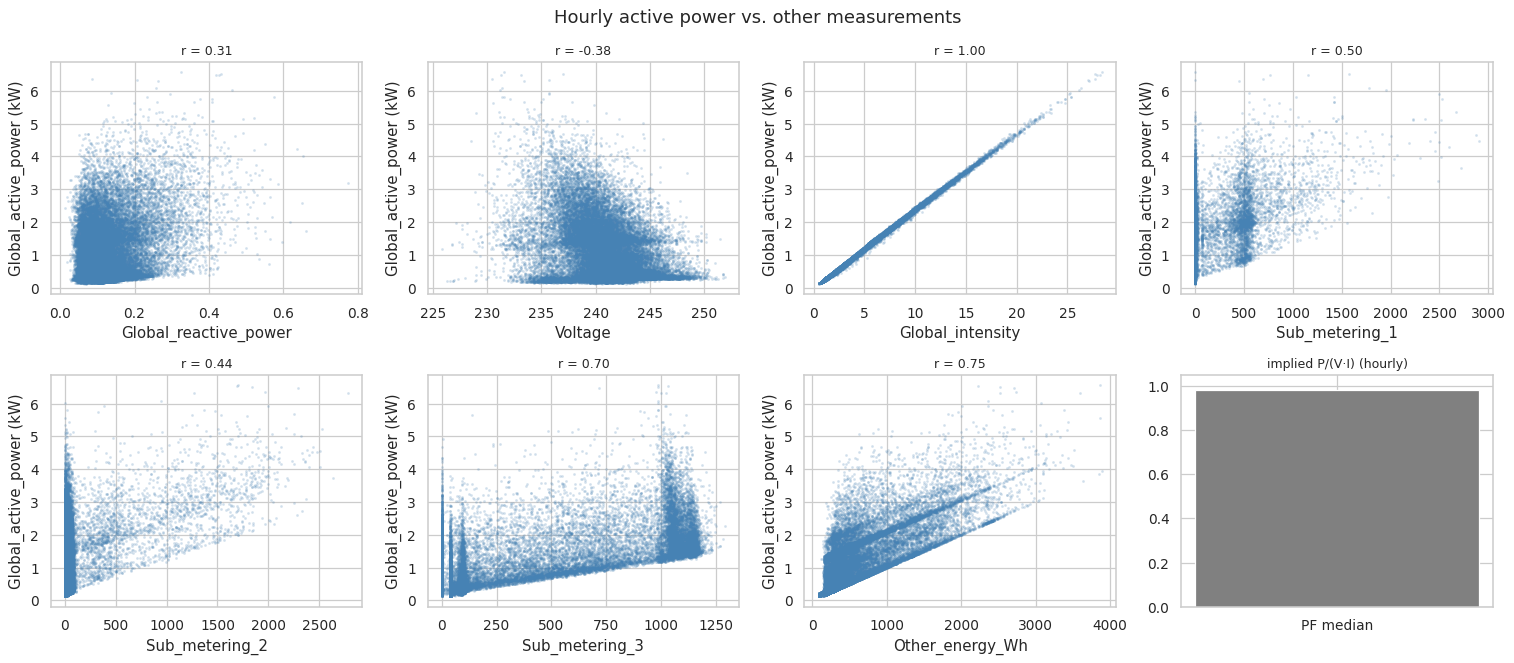

In [ ]:
ex_cols = ["Global_reactive_power", "Voltage", "Global_intensity", "Sub_metering_1", "Sub_metering_2", "Sub_metering_3", "Other_energy_Wh"]
hv_all = hourly.dropna(subset=[TARGET] + ex_cols)
c3 = pd.DataFrame({"pearson_same_hour": hv_all[ex_cols].corrwith(hv_all[TARGET]),
                   "spearman_same_hour": hv_all[ex_cols].corrwith(hv_all[TARGET], method="spearman")})
lagged = pd.concat([hourly[ex_cols].shift(1), hourly[TARGET]], axis=1).dropna()
c3["pearson_prev_hour_vs_target"] = lagged[ex_cols].corrwith(lagged[TARGET])
by_year = {yr_: g[ex_cols].corrwith(g[TARGET]) for yr_, g in hv_all.groupby(hv_all.index.year) if len(g) > 2000}
stab = pd.DataFrame(by_year).round(2)
display(c3.round(3)); display(stab.rename_axis("same-hour Pearson by year")); save_table(c3.round(4), "Q3_correlations")
pf = (hv_all[TARGET] * 1000 / (hv_all["Voltage"] * hv_all["Global_intensity"])).replace([np.inf, -np.inf], np.nan).dropna()
fig, ax = plt.subplots(2, 4, figsize=(17, 7.5)); ax = ax.ravel()
for a, c in zip(ax, ex_cols):
    a.scatter(hv_all[c], hv_all[TARGET], s=2, alpha=.15, color="steelblue"); a.set_xlabel(c); a.set_ylabel("Global_active_power (kW)")
    a.set_title(f"r = {c3.loc[c,'pearson_same_hour']:.2f}", fontsize=10)
ax[-1].bar(["PF median"], [pf.median()], color="gray"); ax[-1].set_ylim(0, 1.05); ax[-1].set_title("implied P/(V·I) (hourly)", fontsize=10)
fig.suptitle("Hourly active power vs. other measurements"); fig.tight_layout(); save_fig(fig, "13_Q3_relationships"); plt.show()
for c, r in c3["pearson_same_hour"].items(): record("Q3", f"pearson_{c}", r)
s = c3["pearson_same_hour"].abs().sort_values(ascending=False)

**Interpretation**

At the same hour, `Global_intensity` has a correlation of 0.999 with active power, followed by `Other_energy_Wh` (0.755) and `Sub_metering_3` (0.696). `Sub_metering_1` (0.497), `Sub_metering_2` (0.440) and `Global_reactive_power` (0.312) are weaker, and `Voltage` is negatively correlated (−0.379). The near-perfect value for `Global_intensity` is expected because active power is approximately voltage × current × power factor, and the implied ratio of active power to voltage × current has a median of 0.98. Voltage and active power move in opposite directions. A voltage drop under heavier load is a possible explanation, but it was not tested and other factors could contribute, so this is not evidence of causation. `Other_energy_Wh` is calculated as active-power energy minus the three sub-meters, so its correlation is partly built into its definition. Pearson and Spearman values are close for most variables. `Sub_metering_2` is the exception (Pearson 0.440, Spearman 0.188), which suggests that its association is driven by a small number of large values and not by a consistent monotonic relationship, in line with its zero-heavy distribution.

The coefficients keep their sign and approximate size across years. `Voltage` varies most (−0.31 in 2007, −0.47 in 2008), and `Global_reactive_power` falls from 0.39 in 2007 to 0.26 in 2010. The largest range across years for any variable is 0.16.

For forecasting, only information from the preceding hour is available, and the previous-hour correlations with the target are lower: 0.714 for `Global_intensity`, 0.632 for `Other_energy_Wh`, 0.455 for `Sub_metering_3`, 0.297 for `Sub_metering_1`, 0.251 for `Sub_metering_2`, 0.237 for `Global_reactive_power` and −0.288 for `Voltage`. The value for `Global_intensity` is close to the lag-1 autocorrelation of active power itself (0.72 in Question 4). Because the two variables are almost collinear within the same hour, previous-hour current probably carries much the same information as previous-hour power.

### Q4. Which previous hours are most informative about current electricity consumption?

This question examines the relationship between active power in the current hour and earlier hours. Autocorrelation is calculated for lags from 1 to 200 hours, with additional plots for selected lags including 1, 24, and 168 hours. Partial autocorrelation is used to examine the contribution of a lag after accounting for shorter lags.

Only earlier measurements are used in these comparisons. Strong correlations at particular lags can help identify useful inputs for the forecasting models.


,lag_hours,autocorrelation,partial_autocorr,R2_of_simple_lag_regression
0,1,0.720,0.720,0.518
1,2,0.473,-0.093,0.224
2,3,0.294,-0.024,0.086
3,6,0.020,-0.002,0.000
4,12,0.242,0.024,0.059
5,24,0.435,0.086,0.189
6,48,0.402,0.054,0.162
7,168,0.470,0.061,0.221


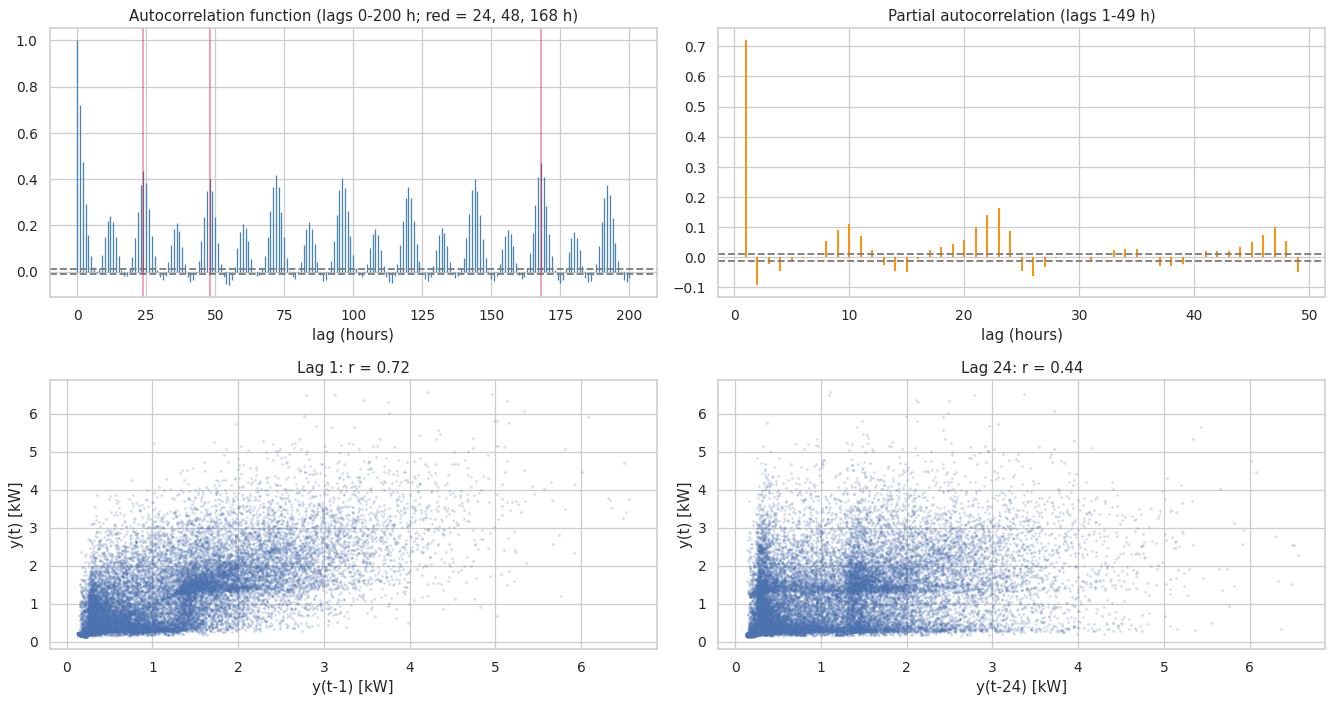

In [ ]:
K = 200
acf = np.array([1.0] + [y_explore.corr(y_explore.shift(k)) for k in range(1, K + 1)])
pacf = fe.partial_autocorrelation(acf)
sel = [1, 2, 3, 6, 12, 24, 48, 168]
lagtab = pd.DataFrame({"lag_hours": sel, "autocorrelation": acf[sel], "partial_autocorr": pacf[sel], "R2_of_simple_lag_regression": acf[sel] ** 2})
display(lagtab.round(3)); save_table(lagtab.round(4), "Q4_lag_correlations", index=False)
ci = 1.96 / np.sqrt(y_explore.notna().sum())
fig, ax = plt.subplots(2, 2, figsize=(15, 8))
ax[0, 0].vlines(range(K + 1), 0, acf, color="steelblue", lw=1); ax[0, 0].axhline(ci, ls="--", c="gray"); ax[0, 0].axhline(-ci, ls="--", c="gray")
for k in (24, 48, 168): ax[0, 0].axvline(k, c="crimson", alpha=.4)
ax[0, 0].set_title("Autocorrelation function (lags 0-200 h; red = 24, 48, 168 h)"); ax[0, 0].set_xlabel("lag (hours)")
ax[0, 1].vlines(range(1, 50), 0, pacf[1:50], color="darkorange"); ax[0, 1].axhline(ci, ls="--", c="gray"); ax[0, 1].axhline(-ci, ls="--", c="gray"); ax[0, 1].set_title("Partial autocorrelation (lags 1-49 h)"); ax[0, 1].set_xlabel("lag (hours)")
for a, k in zip(ax[1], (1, 24)):
    d_ = pd.concat([y_explore, y_explore.shift(k)], axis=1).dropna(); a.scatter(d_.iloc[:, 1], d_.iloc[:, 0], s=2, alpha=.15)
    a.set_xlabel(f"y(t-{k}) [kW]"); a.set_ylabel("y(t) [kW]"); a.set_title(f"Lag {k}: r = {acf[k]:.2f}")
fig.tight_layout(); save_fig(fig, "14_Q4_lag_analysis"); plt.show()
for k in sel: record("Q4", f"acf_lag_{k}", acf[k])
top_pacf = np.argsort(-np.abs(pacf[1:K + 1]))[:4] + 1

**Interpretation**

Active power is persistent over short lags. The autocorrelation is 0.72 at lag 1 (a lag-1 linear regression would give R² ≈ 0.52), 0.47 at lag 2 and 0.29 at lag 3, and it falls to 0.02 at lag 6. It then rises with the daily cycle: 0.24 at lag 12, 0.44 at lag 24, 0.40 at lag 48 and 0.47 at lag 168, the same hour one week earlier. The values at lags 24, 48 and 168 are comparable to the value at lag 2, so the same hour on previous days or the previous week is about as informative on its own as the hour two steps back.

The partial autocorrelation shows what each lag adds once shorter lags are accounted for. Lag 1 dominates (0.72). Lags 2 and 3 are small and negative (−0.09 and −0.02), and lags 24 and 168 contribute 0.09 and 0.06, both above the approximate ±0.012 band for white noise. That band is narrow because there are 27,476 observations, so the size of a partial value is more informative than whether it exceeds the band. After lag 1, the largest partial values are at lags 10, 22 and 23 (0.11, 0.14 and 0.16), so the daily lags add a modest amount beyond the recent hours.

For feature engineering, these results support lag 1 as the main autoregressive feature, with lags 24 and 168 for daily and weekly repetition and lags 2, 3, 6, 12 and 48 as supplementary candidates. They also justify persistence (lag 1) and the seasonal naive forecasts (lags 24 and 168) as baselines. All lag features come from earlier hours, so no future information is used. Autocorrelation measures only linear association averaged over the exploration window, so the selected lags are not guaranteed to be the best for every model.

### Q5. What do moving averages reveal about consumption, and can they help predict the next hour?

Trailing averages over 3, 6, 24, and 168 hours are compared with the hourly series. Short windows respond more quickly to changes, while longer windows show broader patterns. The analysis measures how much each window smooths the data and whether it follows changes with a delay.

For prediction, the rolling window is shifted so it contains only values known before the target hour. An unshifted average containing the target hour would give an unfair advantage and is not used as a forecasting input.


,window_h,sd_ratio_MA_to_y,delay_h_best_match,theory_delay_(w-1)/2,corr_unshifted(LEAKY),corr_shifted_MA(t-1)_vs_y(t),MAE_as_forecast
0,3,0.871,1,1.0,0.839,0.569,0.571
1,6,0.736,3,2.5,0.614,0.392,0.688
2,24,0.474,12,11.5,0.409,0.359,0.676
3,168,0.362,84,83.5,0.337,0.329,0.689


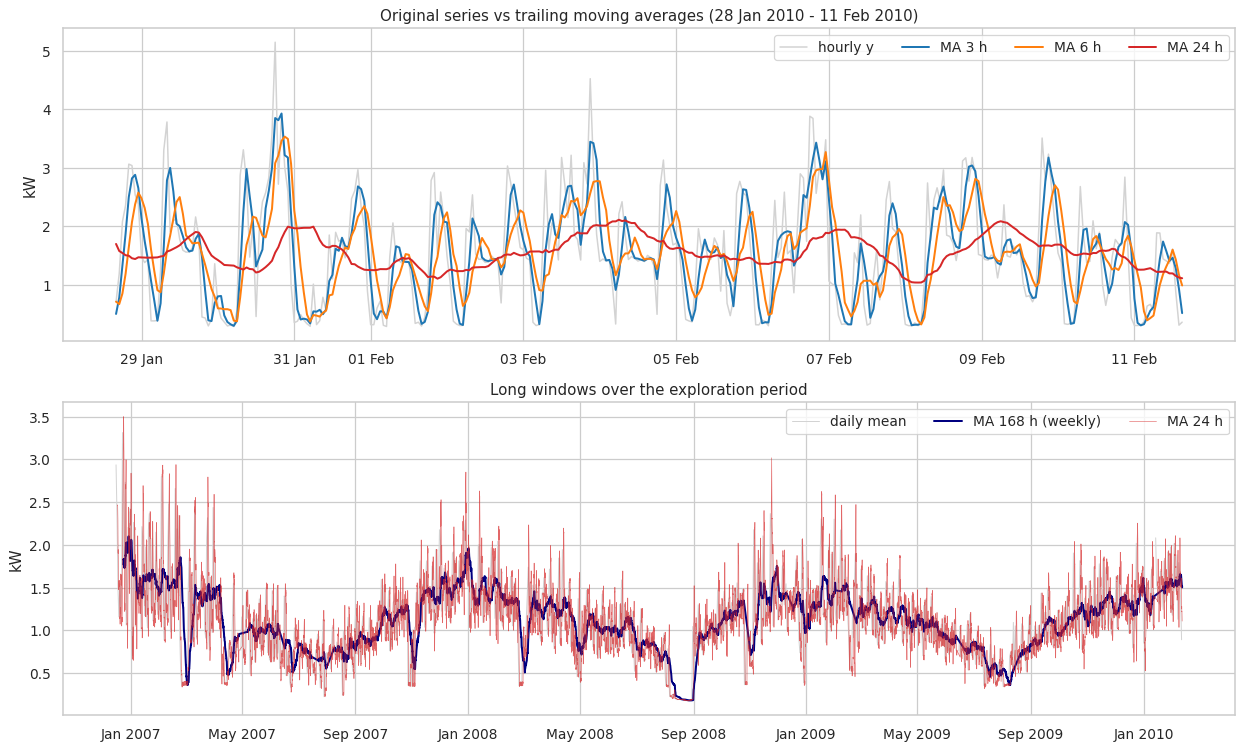

In [ ]:
W = [3, 6, 24, 168]
ma = {w: y_explore.rolling(w, min_periods=w).mean() for w in W}
ma_shift = {w: ma[w].shift(1) for w in W}                          # uses y(t-w ... t-1) only
rows5 = []
for w in W:
    both = pd.concat([y_explore, ma[w]], axis=1).dropna(); bs = pd.concat([y_explore, ma_shift[w]], axis=1).dropna()
    cc = [(L, y_explore.shift(L).corr(ma[w])) for L in range(0, w + 1 if w <= 48 else 100)]
    best_lag = max(cc, key=lambda x: x[1])[0]
    rows5.append({"window_h": w, "sd_ratio_MA_to_y": ma[w].std() / y_explore.std(), "delay_h_best_match": best_lag, "theory_delay_(w-1)/2": (w - 1) / 2,
                  "corr_unshifted(LEAKY)": both.iloc[:, 0].corr(both.iloc[:, 1]), "corr_shifted_MA(t-1)_vs_y(t)": bs.iloc[:, 0].corr(bs.iloc[:, 1]),
                  "MAE_as_forecast": (bs.iloc[:, 0] - bs.iloc[:, 1]).abs().mean()})
q5 = pd.DataFrame(rows5); display(q5.round(3)); save_table(q5.round(4), "Q5_moving_average_results", index=False)
# plot window: latest 14-day block in the exploration period that is fully observed
obs_cnt = y_explore.notna().rolling(336).sum(); end_w = obs_cnt[obs_cnt == 336].index[-1]; win = slice(end_w - pd.Timedelta(hours=335), end_w)
fig, ax = plt.subplots(2, 1, figsize=(14, 8.5))
ax[0].plot(y_explore[win], color="lightgray", lw=1.2, label="hourly y");
for w, c in zip([3, 6, 24], ["tab:blue", "tab:orange", "tab:red"]): ax[0].plot(ma[w][win], color=c, lw=1.6, label=f"MA {w} h")
ax[0].set_title(f"Original series vs trailing moving averages ({end_w - pd.Timedelta(hours=335):%d %b %Y} - {end_w:%d %b %Y})"); ax[0].set_ylabel("kW"); ax[0].legend(ncol=4)
ax[0].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax[1].plot(y_explore.resample("D").mean(), color="lightgray", lw=.8, label="daily mean"); ax[1].plot(ma[168].dropna(), color="navy", lw=1.6, label="MA 168 h (weekly)"); ax[1].plot(ma[24].dropna(), color="tab:red", lw=.5, alpha=.7, label="MA 24 h")
ax[1].set_title("Long windows over the exploration period"); ax[1].set_ylabel("kW"); ax[1].legend(ncol=3); ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.tight_layout(); save_fig(fig, "15_Q5_moving_averages"); plt.show()
for r in rows5: record("Q5", f"corr_shifted_MA{r['window_h']}", r["corr_shifted_MA(t-1)_vs_y(t)"])
r3, r24, r168 = [q5[q5.window_h == w].iloc[0] for w in (3, 24, 168)]

**Interpretation**

*Smoothing.* The standard deviation of the moving average, relative to that of the hourly series, is 0.87 for the 3-hour window, 0.74 for 6 hours, 0.47 for 24 hours and 0.36 for 168 hours. In kW this is 0.93 for the hourly series against 0.81, 0.44 and 0.34 for the 3-, 24- and 168-hour averages. The 24-hour and 168-hour averages remove most of the daily rhythm and show slower changes in level, as in the lower panel of the figure.

*Delay.* A trailing average responds late. The best alignment with the original series is at a delay of 1 hour for the 3-hour window, 3 hours for the 6-hour window, 12 hours for the 24-hour window and 84 hours for the 168-hour window. These are close to the theoretical delay of (w − 1)/2, which is 1, 2.5, 11.5 and 83.5 hours. Wide windows therefore lag behind sudden changes such as the start of an evening peak.

*Use for forecasting.* The unshifted averages include the current hour and cannot be used as predictors. Their correlation with the current value is 0.84 (3 h), 0.61 (6 h), 0.41 (24 h) and 0.34 (168 h), partly because the target is inside the window. The shifted averages, which use earlier hours only, have correlations of 0.57, 0.39, 0.36 and 0.33. Used directly as one-hour-ahead forecasts, they give MAEs of 0.571 kW (3 h), 0.688 kW (6 h), 0.676 kW (24 h) and 0.689 kW (168 h), so the error does not fall steadily as the window changes. The 3-hour average is the most accurate of the four, but its correlation (0.57) is lower than that of the previous hour alone (0.72, Question 4). Short windows keep useful information about the recent level, while long windows describe context but are too slow to forecast the next hour by themselves. They are better used as additional features, always shifted so that the target hour is excluded.

### Q6. Do lagged values and moving averages improve one-hour-ahead forecasts?

This question compares simple forecasts based on the previous hour, the same hour on an earlier day or week, and shifted moving averages. It also tests an hour-of-week average calculated from earlier observations. All methods are evaluated on the same available hours in the exploratory period using MAE, RMSE, and R².

The comparison helps determine which historical patterns are useful before fitting the machine learning models.


,MAE,RMSE,R2,MAE_vs_hist_mean_%
Persistence (lag 1),0.453,0.700,0.428,-21.973
Shifted MA 3 h,0.574,0.820,0.216,-1.116
Historical hour-of-week mean,0.581,0.788,0.276,0.000
Seasonal naive 168 h,0.627,0.941,-0.032,8.036
Seasonal naive 24 h,0.656,0.976,-0.111,12.990
Shifted MA 24 h,0.675,0.874,0.110,16.193
Shifted MA 168 h,0.683,0.877,0.103,17.664
Shifted MA 6 h,0.691,0.918,0.017,19.018


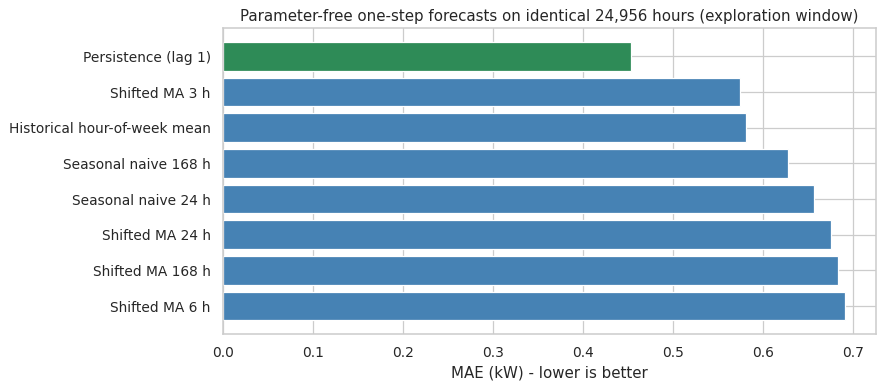

In [ ]:
how = y_explore.index.dayofweek * 24 + y_explore.index.hour
hist_mean = y_explore.groupby(how).transform(lambda s: s.shift(1).expanding(min_periods=4).mean())
cand = {"Persistence (lag 1)": y_explore.shift(1), "Seasonal naive 24 h": y_explore.shift(24), "Seasonal naive 168 h": y_explore.shift(168),
        **{f"Shifted MA {w} h": ma_shift[w] for w in W}, "Historical hour-of-week mean": hist_mean}
dfc = pd.concat([y_explore.rename("y"), pd.DataFrame(cand)], axis=1).dropna()
q6 = pd.DataFrame({k: mdl.regression_metrics(dfc["y"], dfc[k]) for k in cand}).T[["MAE", "RMSE", "R2"]].sort_values("MAE")
q6["MAE_vs_hist_mean_%"] = (q6["MAE"] / q6.loc["Historical hour-of-week mean", "MAE"] - 1) * 100
display(q6.round(3)); save_table(q6.round(4), "Q6_simple_predictors")
fig, ax = plt.subplots(figsize=(10, 4.5)); colors = ["seagreen" if k.startswith("Persist") else "steelblue" for k in q6.index]
ax.barh(q6.index[::-1], q6["MAE"][::-1], color=colors[::-1]); ax.set_xlabel("MAE (kW) - lower is better"); ax.set_title(f"Parameter-free one-step forecasts on identical {len(dfc):,} hours (exploration window)")
fig.tight_layout(); save_fig(fig, "16_Q6_simple_predictors"); plt.show()
for k, v in q6["MAE"].items(): record("Q6", f"MAE_{k}", v)

**Interpretation**

On the 24,956 hours for which every method has a forecast, persistence (the previous hour) is the most accurate simple method on all three metrics: MAE 0.453 kW, RMSE 0.700 kW and R² 0.428. The next best by MAE are the 3-hour shifted average (0.574 kW, R² 0.216) and the historical hour-of-week mean (0.581 kW, R² 0.276), so persistence has an MAE about 22% lower than the latter. The hour-of-week mean has a lower RMSE (0.788 kW) than the 3-hour average (0.820 kW), so the ranking of these two depends on the metric. The seasonal naive forecasts are weaker, with MAE 0.627 kW at 168 hours and 0.656 kW at 24 hours. Their R² values are negative (−0.032 and −0.111), meaning that their squared error is larger than that of always predicting the mean of the evaluated hours. The 6-, 24- and 168-hour shifted averages have MAEs of 0.691, 0.675 and 0.683 kW and R² between 0.017 and 0.110.

For a one-hour-ahead horizon, the most recent value is therefore more useful than a moving average or the same hour on a previous day or week, and moving averages used alone do not improve on it. The hour-of-week mean, the 24-hour and 168-hour lags and the rolling means still contain different information (the periodic pattern and the longer-term level). Whether they improve forecasts when combined with recent values is a question for the supervised models in Sections 12 to 17. A first indication is that default Ridge Regression, which uses all features, reaches a validation MAE of 0.4075 kW against 0.4635 kW for persistence (Section 14). The MAE of the 3-hour average here (0.574 kW) differs slightly from that in Question 5 (0.571 kW) because this comparison uses only hours where all methods are available. These figures come from the exploration window and are not test-set results.

In [ ]:
q_results = pd.DataFrame(qrows); save_table(q_results.round(5), "analytical_question_results", index=False)
print(f"{q_results.question.nunique()} analytical questions answered; {len(q_results)} quantitative results saved.")

6 analytical questions answered; 35 quantitative results saved.


## 12. Feature engineering

The hourly data is converted into a table with one row for each hour to be predicted. For target hour $T$, all measured input values must come from hour $T-1$ or earlier.

The feature set includes:
- Earlier active-power values at selected hourly lags.
- Trailing means and standard deviations over 3, 6, 24, and 168 hours.
- Earlier readings of the other electrical variables.
- Calendar information for the hour being forecast, including hour, weekday, and month.

Rolling calculations are shifted before use. Hours with missing target values or unavailable required inputs are excluded. The code reports how many rows are removed, including the initial hours needed to establish the longest lag.


In [ ]:
X, y, build_info = fe.build_supervised_frame(filled, hourly[TARGET], horizon=HORIZON)
feat_dict = fe.feature_dictionary(X.columns, horizon=HORIZON)
display(pd.Series(build_info, name="rows").to_frame())
print("Supervised matrix:", X.shape, "| target:", y.name, "| period:", X.index.min(), "->", X.index.max())

# --- explicit alignment checks on the real data -------------------------------------------------
assert (X["gap_lag1"] == filled[TARGET].shift(1).loc[X.index]).all()
assert (X["gap_lag24"] == filled[TARGET].shift(24).loc[X.index]).all()
assert np.allclose(X["gap_roll_mean_3h"], filled[TARGET].shift(1).rolling(3).mean().loc[X.index])    # window ends at T-1, excludes y_T
assert (X["hour"] == X.index.hour).all() and (X["is_weekend"] == (X.index.dayofweek >= 5)).all()
assert fe.leakage_check(filled, hourly[TARGET], horizon=HORIZON), "feature leakage detected"
assert fe.leakage_check(filled, hourly[TARGET], horizon=6), "feature leakage detected (h=6)"
print("Alignment assertions and corrupt-the-future leakage tests passed (horizon 1 and 6).")
T0 = X.index[400]
display(pd.DataFrame({"target y(T)": [y[T0]], "gap_lag1 = y(T-1)": [X.loc[T0, "gap_lag1"]], "y(T-1) from series": [hourly[TARGET].loc[T0 - pd.Timedelta(hours=1)]],
                      "roll_mean_3h": [X.loc[T0, "gap_roll_mean_3h"]], "mean y(T-3..T-1)": [hourly[TARGET].loc[T0 - pd.Timedelta(hours=3):T0 - pd.Timedelta(hours=1)].mean()]}, index=[T0]).round(4))
imp_inputs = impute_flags[TARGET].astype(int).shift(1).rolling(168, min_periods=1).sum().loc[X.index] > 0
display(feat_dict); save_table(feat_dict, "feature_dictionary", index=False)

,rows
rows_before_dropping,34589
rows_missing_target,438
rows_missing_inputs,1745
rows_kept,32807


Supervised matrix: (32807, 31) | target: Global_active_power_t_plus_1h | period: 2006-12-23 18:00:00 -> 2010-11-26 20:00:00
Alignment assertions and corrupt-the-future leakage tests passed (horizon 1 and 6).


,target y(T),gap_lag1 = y(T-1),y(T-1) from series,roll_mean_3h,mean y(T-3..T-1)
2007-01-09 10:00:00,1.3492,1.8684,1.8684,2.1303,2.1303


,feature,definition,calculation,forecasting_purpose
0,gap_lag1,Global_active_power 1 hour(s) before the forecast origin (lag1 = last known hour),shift(1) of hourly mean power,autoregressive memory; k=24/168 capture daily/weekly cycle
1,gap_lag2,Global_active_power 2 hour(s) before the forecast origin (lag1 = last known hour),shift(2) of hourly mean power,autoregressive memory; k=24/168 capture daily/weekly cycle
2,gap_lag3,Global_active_power 3 hour(s) before the forecast origin (lag1 = last known hour),shift(3) of hourly mean power,autoregressive memory; k=24/168 capture daily/weekly cycle
3,gap_lag6,Global_active_power 6 hour(s) before the forecast origin (lag1 = last known hour),shift(6) of hourly mean power,autoregressive memory; k=24/168 capture daily/weekly cycle
4,gap_lag12,Global_active_power 12 hour(s) before the forecast origin (lag1 = last known hour),shift(12) of hourly mean power,autoregressive memory; k=24/168 capture daily/weekly cycle
5,gap_lag24,Global_active_power 24 hour(s) before the forecast origin (lag1 = last known hour),shift(24) of hourly mean power,autoregressive memory; k=24/168 capture daily/weekly cycle
6,gap_lag48,Global_active_power 48 hour(s) before the forecast origin (lag1 = last known hour),shift(48) of hourly mean power,autoregressive memory; k=24/168 capture daily/weekly cycle
7,gap_lag168,Global_active_power 168 hour(s) before the forecast origin (lag1 = last known hour),shift(168) of hourly mean power,autoregressive memory; k=24/168 capture daily/weekly cycle
8,gap_roll_mean_3h,Mean of the last 3h hourly target values up to the origin,shift(1).rolling(3).mean(),smoothed recent level; reduces hourly noise
9,gap_roll_std_3h,Std. deviation of the last 3h hourly target values up to the origin,shift(1).rolling(3).std(),recent volatility


**Interpretation**

The supervised table has 32,807 rows and 31 features, covering 23 December 2006 18:00 to 26 November 2010 20:00. Of the 34,589 hourly rows, 1,782 (5.2%) were dropped and 94.8% were kept. In 438 of the dropped rows the target is missing, and in 1,745 the inputs are incomplete, including the first 168 hours needed for the weekly lag; these two groups overlap, so they sum to more than 1,782. The 31 features comprise 8 target lags, 8 rolling means and standard deviations, 7 lagged values of the other measurements and 8 calendar features.

The checks on real rows confirm the alignment. For the target hour 9 January 2007 10:00, `gap_lag1` (1.8684 kW) equals the value of the preceding hour in the original series, and the 3-hour rolling mean (2.1303 kW) equals the mean of the three previous hours, so the target hour is not included. The leakage test passed for forecast horizons of 1 and 6 hours. Only 3.58% of the retained rows depend on a forward-filled input within their 168-hour look-back, so the filling rule affects few training examples.

## 13. Train, validation and test splitting

The observations are divided in chronological order: the earliest 70% for training, the next 15% for validation, and the final 15% for testing. The training set is used to fit models and tune parameters; validation results are used to compare candidate models.

A random split would mix earlier and later periods and could make forecasts appear more accurate than they would be in practice. Hyperparameter tuning therefore uses expanding-window time-series cross-validation within the training period.


In [ ]:
splits = mdl.chronological_split(X, y, TRAIN_FRAC, VAL_FRAC)
split_tbl = mdl.split_summary(splits); display(split_tbl); save_table(split_tbl, "split_summary", index=False)
(Xtr, ytr), (Xva, yva), (Xte, yte) = splits["train"], splits["val"], splits["test"]
assert Xtr.index.max() < Xva.index.min() and Xva.index.max() < Xte.index.min()
assert explore_end <= Xte.index.min(), "exploration (Q4-Q6) window must end before the test period"
assert len(Xtr) + len(Xva) + len(Xte) == len(X)
print("Chronological separation verified: train < validation < test; Q4-Q6 exploration ended before the test period.")

# why shuffling is unrealistic: compare random vs chronological hold-out on TRAIN+VALIDATION only (test untouched)
from sklearn.model_selection import train_test_split
Xtv, ytv = pd.concat([Xtr, Xva]), pd.concat([ytr, yva])
Xa, Xb, ya, yb = train_test_split(Xtv, ytv, test_size=0.2, shuffle=True, random_state=SEED)
cut = int(len(Xtv) * 0.8)
m_rand = mdl.build_ridge_pipeline(1.0).fit(Xa, ya); m_chron = mdl.build_ridge_pipeline(1.0).fit(Xtv.iloc[:cut], ytv.iloc[:cut])
shuffle_demo = pd.DataFrame({"random shuffled 80/20": mdl.regression_metrics(yb, m_rand.predict(Xb)),
                             "chronological 80/20": mdl.regression_metrics(ytv.iloc[cut:], m_chron.predict(Xtv.iloc[cut:]))}).T[["MAE", "RMSE", "R2"]]
display(shuffle_demo.round(4))
tscv_rows = [{"fold": i + 1, "train_end": Xtr.index[tr[-1]], "validation_start": Xtr.index[va[0]], "validation_end": Xtr.index[va[-1]], "n_train": len(tr), "n_valid": len(va)}
             for i, (tr, va) in enumerate(__import__("sklearn.model_selection", fromlist=["TimeSeriesSplit"]).TimeSeriesSplit(n_splits=TUNING_CV_SPLITS).split(Xtr))]
display(pd.DataFrame(tscv_rows))

,partition,start,end,n_rows,target_mean,target_std
0,train,2006-12-23 18:00:00,2009-09-02 11:00:00,22964,1.089172,0.931340
1,val,2009-09-02 12:00:00,2010-04-13 02:00:00,4921,1.227544,0.891488
2,test,2010-04-13 03:00:00,2010-11-26 20:00:00,4922,0.960553,0.707872


Chronological separation verified: train < validation < test; Q4-Q6 exploration ended before the test period.


,MAE,RMSE,R2
random shuffled 80/20,0.4102,0.5839,0.5999
chronological 80/20,0.3936,0.5547,0.6014


,fold,train_end,validation_start,validation_end,n_train,n_valid
0,1,2007-07-12 21:00:00,2007-07-12 22:00:00,2008-01-20 08:00:00,4596,4592
1,2,2008-01-20 08:00:00,2008-01-20 09:00:00,2008-07-29 16:00:00,9188,4592
2,3,2008-07-29 16:00:00,2008-07-29 17:00:00,2009-02-06 03:00:00,13780,4592
3,4,2009-02-06 03:00:00,2009-02-06 04:00:00,2009-09-02 11:00:00,18372,4592


**Interpretation**

The chronological split gives 22,964 training rows (23 December 2006 to 2 September 2009), 4,921 validation rows (2 September 2009 to 13 April 2010) and 4,922 test rows (13 April 2010 to 26 November 2010). The assertions confirm that the partitions follow one another in time without overlap. The mean target is 1.089 kW in training, 1.228 kW in validation and 0.961 kW in the test set, so the test mean is 11.8% below the training mean. The standard deviation falls from 0.931 kW (training) and 0.891 kW (validation) to 0.708 kW (test). The test period (13 April to 26 November) excludes the winter months, which have the highest monthly means in Section 10, and this probably contributes to the difference, although it was not tested. The lower variability of the test target also matters when R² is compared across partitions, because R² is measured against the variance of the period being evaluated.

Hyperparameter tuning uses four expanding-window folds inside the training set, with training sizes from 4,596 to 18,372 rows and 4,592 validation rows per fold. Each fold is validated on data later than its training data. The notebook fits scaling (and any imputing) inside the sklearn pipelines on training folds only; this follows from the pipeline design and is not checked by a separate assertion.

As a check on shuffling, Ridge Regression was fitted on the combined training and validation data with a random 80/20 split and with a chronological 80/20 split. The random split gave an MAE of 0.4102 kW and R² of 0.600, and the chronological split gave 0.3936 kW and 0.601. The random split was therefore not more optimistic in this case. The two hold-out sets contain different periods, so the comparison does not show that shuffling is harmless. Chronological evaluation is used because shuffled training would use later observations to predict earlier ones, which cannot happen in practice.

The exploration window for Questions 4 to 6 ends on 11 February 2010, which is inside the validation period. The validation set is therefore not completely separate from the lag analysis. The test set was not used.

## 14. Forecasting models

The experiments use the same one-hour-ahead target and chronological data partitions. Simple forecasts provide reference points before evaluating the machine learning models.

| Experiment | Method | Purpose |
|---|---|---|
| E0a | Persistence: previous hour | Tests whether the latest reading is sufficient |
| E0b–E0c | Seasonal naive: 24-hour and 168-hour lags | Tests daily and weekly repetition |
| E1 | Ridge Regression | Fits a regularized linear model using engineered features |
| E2 | Random Forest | Models nonlinear relationships between historical measurements and calendar features |
| E3–E4 | Tuned Ridge and Random Forest | Compares configurations selected through time-series cross-validation |
| E5 | Tuned Ridge with target-history features only | Tests the value of additional electrical and calendar variables |

Ridge Regression is computationally efficient and can handle correlated inputs after scaling, but it models linear relationships. Random Forest can capture more complex patterns without scaling, although it is slower and cannot reliably extrapolate beyond the training range. LSTM was not included because the assignment can be addressed with simpler models that are easier to train, compare, and reproduce.


In [ ]:
FEATS_ALL = list(X.columns)
FEATS_TARGET_ONLY = [c for c in X.columns if c.startswith("gap_")]
experiment_rows, all_preds, fitted_models = [], {}, {}
def add_experiment(exp_id, *args, **kwargs):
    row, preds = mdl.run_experiment(exp_id, *args, splits=splits, **kwargs)
    experiment_rows.append(row); all_preds[exp_id] = preds
    return row

add_experiment("E0a", "Persistence (lag 1)", baseline_column="gap_lag1", feature_config="gap_lag1", hyperparameters="none")
add_experiment("E0b", "Seasonal naive 24 h", baseline_column="gap_lag24", feature_config="gap_lag24", hyperparameters="none")
add_experiment("E0c", "Seasonal naive 168 h", baseline_column="gap_lag168", feature_config="gap_lag168", hyperparameters="none")
ridge0 = mdl.build_ridge_pipeline(alpha=1.0)
add_experiment("E1", "Ridge (default)", estimator=ridge0, features=FEATS_ALL, feature_config=f"all {len(FEATS_ALL)} features", hyperparameters="alpha=1.0"); fitted_models["E1"] = (ridge0, FEATS_ALL)
rf0 = mdl.build_rf_pipeline(seed=SEED)
add_experiment("E2", "Random Forest (default)", estimator=rf0, features=FEATS_ALL, feature_config=f"all {len(FEATS_ALL)} features", hyperparameters="n_estimators=100, max_depth=None, min_samples_leaf=1, max_features=1.0"); fitted_models["E2"] = (rf0, FEATS_ALL)
display(pd.DataFrame(experiment_rows).set_index("experiment")[["model", "Val_MAE", "Val_RMSE", "Val_R2", "runtime_s"]].round(4))

,model,Val_MAE,Val_RMSE,Val_R2,runtime_s
experiment,,,,,
E0a,Persistence (lag 1),0.4635,0.6915,0.3982,0.00
E0b,Seasonal naive 24 h,0.6639,0.9602,-0.1604,0.00
E0c,Seasonal naive 168 h,0.5909,0.8723,0.0424,0.00
E1,Ridge (default),0.4075,0.5713,0.5892,0.02
E2,Random Forest (default),0.3530,0.5169,0.6638,37.79


**Interpretation**

On the validation set, persistence is the best of the three baselines (MAE 0.4635 kW, RMSE 0.6915 kW, R² 0.398). The seasonal naive forecasts are less accurate: MAE is 0.6639 kW for 24 hours and 0.5909 kW for 168 hours, with R² of −0.160 and 0.042. This agrees with the exploratory comparison in Question 6, where the previous hour was also the best simple predictor, and indicates that at a one-hour horizon the latest value carries more information than the value from the same hour a day or a week earlier.

Default Ridge Regression (E1, α = 1, 31 features) reduces validation MAE to 0.4075 kW and RMSE to 0.5713 kW and raises R² to 0.589, an MAE about 12% lower than persistence. The default Random Forest (E2) reaches an MAE of 0.3530 kW, RMSE of 0.5169 kW and R² of 0.664. This is about 24% lower in MAE than persistence and about 13% lower than Ridge, but training takes 37.79 s against 0.02 s for Ridge. The Random Forest's training MAE is much lower than its validation MAE (0.1297 against 0.3530 kW; Section 17), a gap that is consistent with overfitting at the default settings. These are validation results, used to compare models, and not final performance estimates.

## 15. Hyperparameter tuning

Ridge Regression and Random Forest are tuned using four-fold expanding-window `TimeSeriesSplit` on the training data. The search criterion is mean absolute error (MAE).

For Ridge Regression, the search tests 13 regularization strengths between $10^{-3}$ and $10^3$. For Random Forest, a randomized search tests eight configurations drawn from choices for the number of trees, maximum depth, minimum leaf size, and maximum features. This limited search keeps training practical while allowing a direct comparison of different settings.

The best configurations are then assessed on the validation period. The final test period is reserved for reporting forecast performance.


In [ ]:
ridge_search, ridge_cv, ridge_sum = mdl.tune_model(mdl.build_ridge_pipeline(), {"model__alpha": np.logspace(-3, 3, 13)}, Xtr[FEATS_ALL], ytr,
                                                    search="grid", n_splits=TUNING_CV_SPLITS, seed=SEED)
display(ridge_cv.head(5).round(4)); print(json.dumps({k: (v if not isinstance(v, dict) else {a: float(b) for a, b in v.items()}) for k, v in ridge_sum.items()}, indent=1))

,param_model__alpha,mean_test_score,std_test_score,rank_test_score
0,316.2278,-0.4027,0.0324,1
1,100.0000,-0.4030,0.0322,2
2,31.6228,-0.4032,0.0323,3
3,10.0000,-0.4034,0.0323,4
4,3.1623,-0.4034,0.0323,5


{
 "search": "grid",
 "cv": "TimeSeriesSplit(n_splits=4)",
 "scoring": "neg_mean_absolute_error",
 "n_candidates": 13,
 "n_fits": 52,
 "best_params": {
  "model__alpha": 316.2277660168379
 },
 "best_cv_score": -0.4026684502783531,
 "tuning_seconds": 0.5
}


**Interpretation**

The search selected α = 316.2, with a cross-validated MAE of 0.4027 kW (standard deviation across folds 0.0324 kW). The five best values of α (from 3.16 to 316.2) have mean MAE between 0.4027 and 0.4034 kW, and the difference between the best and worst of the 13 values tested is 0.0008 kW. This is far smaller than the fold-to-fold standard deviation, so the regularisation strength has almost no effect on cross-validated MAE for this feature set, and the choice of 316.2 over neighbouring values has little practical meaning. The best value is not at the edge of the grid, which extends to 1,000. The 52 fits took 0.5 s.

In [ ]:
rf_space = {"model__n_estimators": [50, 100], "model__max_depth": [8, 12], "model__min_samples_leaf": [5, 15], "model__max_features": [0.3, 0.5]}
rf_search, rf_cv, rf_sum = mdl.tune_model(mdl.build_rf_pipeline(seed=SEED), rf_space, Xtr[FEATS_ALL], ytr,
                                           search="random", n_splits=TUNING_CV_SPLITS, n_iter=RF_N_ITER, seed=SEED)
display(rf_cv.round(4)); print(json.dumps(rf_sum, indent=1, default=str))
save_table(ridge_cv.round(5), "tuning_ridge_cv_results", index=False); save_table(rf_cv.round(5), "tuning_rf_cv_results", index=False)

,param_model__n_estimators,param_model__min_samples_leaf,param_model__max_features,param_model__max_depth,mean_test_score,std_test_score,rank_test_score
0,50,15,0.5,12,-0.3635,0.0340,1
1,100,5,0.5,12,-0.3636,0.0350,2
2,100,15,0.3,12,-0.3661,0.0349,3
3,100,5,0.3,12,-0.3669,0.0357,4
4,50,5,0.3,12,-0.3682,0.0360,5
5,100,5,0.5,8,-0.3697,0.0332,6
6,100,5,0.3,8,-0.3722,0.0334,7
7,50,5,0.3,8,-0.3740,0.0328,8


{
 "search": "random",
 "cv": "TimeSeriesSplit(n_splits=4)",
 "scoring": "neg_mean_absolute_error",
 "n_candidates": 8,
 "n_fits": 32,
 "best_params": {
  "model__n_estimators": 50,
  "model__min_samples_leaf": 15,
  "model__max_features": 0.5,
  "model__max_depth": 12
 },
 "best_cv_score": -0.3635139989921863,
 "tuning_seconds": 100.83
}


PosixPath('/home/claude/task1_time_series/outputs/tables/tuning_rf_cv_results.csv')

**Interpretation**

The best of the 8 random candidates (n_estimators = 50, min_samples_leaf = 15, max_features = 0.5, max_depth = 12) has a cross-validated MAE of 0.3635 kW, with a fold-to-fold standard deviation of 0.0340 kW. All eight candidates lie between 0.3635 and 0.3740 kW, a range of 0.0105 kW. The five candidates with max_depth = 12 rank first to fifth and the three with max_depth = 8 rank sixth to eighth, so depth is the setting with the clearest effect in this search. The two best candidates differ by 0.0001 kW, far less than the fold-to-fold variation, so the selected configuration is not clearly better than the second. The selected max_depth of 12 is the largest value in the search space, so deeper forests were not examined. The forest's cross-validated MAE is about 10% lower than that of Ridge (0.3635 against 0.4027 kW). The 32 fits took 100.83 s, and only training data were used.

In [ ]:
a_best = ridge_sum["best_params"]["model__alpha"]
add_experiment("E3", "Ridge (tuned)", estimator=ridge_search.best_estimator_, features=FEATS_ALL, fitted=True, extra_seconds=ridge_sum["tuning_seconds"],
               feature_config=f"all {len(FEATS_ALL)} features", hyperparameters=f"alpha={a_best:.4g}"); fitted_models["E3"] = (ridge_search.best_estimator_, FEATS_ALL)
rf_params = {k.replace("model__", ""): v for k, v in rf_sum["best_params"].items()}
add_experiment("E4", "Random Forest (tuned)", estimator=rf_search.best_estimator_, features=FEATS_ALL, fitted=True, extra_seconds=rf_sum["tuning_seconds"],
               feature_config=f"all {len(FEATS_ALL)} features", hyperparameters=", ".join(f"{k}={v}" for k, v in rf_params.items())); fitted_models["E4"] = (rf_search.best_estimator_, FEATS_ALL)
ridge_t = mdl.build_ridge_pipeline(alpha=a_best)
add_experiment("E5", "Ridge (tuned alpha), target-only features", estimator=ridge_t, features=FEATS_TARGET_ONLY, feature_config=f"{len(FEATS_TARGET_ONLY)} gap_* lag/rolling features",
               hyperparameters=f"alpha={a_best:.4g}"); fitted_models["E5"] = (ridge_t, FEATS_TARGET_ONLY)
tune_tbl = pd.DataFrame([{"model": "Ridge", **{k: ridge_sum[k] for k in ("search", "cv", "n_candidates", "n_fits", "best_cv_score", "tuning_seconds")}, "best_params": str(ridge_sum["best_params"])},
                         {"model": "Random Forest", **{k: rf_sum[k] for k in ("search", "cv", "n_candidates", "n_fits", "best_cv_score", "tuning_seconds")}, "best_params": str(rf_sum["best_params"])}])
display(tune_tbl); save_table(tune_tbl, "tuning_summary", index=False)

,model,search,cv,n_candidates,n_fits,best_cv_score,tuning_seconds,best_params
0,Ridge,grid,TimeSeriesSplit(n_splits=4),13,52,-0.402668,0.50,{'model__alpha': np.float64(316.2277660168379)}
1,Random Forest,random,TimeSeriesSplit(n_splits=4),8,32,-0.363514,100.83,"{'model__n_estimators': 50, 'model__min_samples_leaf': 15, 'model__max_features': 0.5, 'model__max_depth': 12}"


**Interpretation**

The tuning summary records the settings and results of both searches: grid search over 13 values of α for Ridge (52 fits, 0.50 s) and random search over 8 configurations for the Random Forest (32 fits, 100.83 s). Both use `TimeSeriesSplit(n_splits=4)` and MAE as the criterion. The tuned models are evaluated as experiments E3 (Ridge, α = 316.2), E4 (Random Forest) and E5 (Ridge with the 16 target-history features only), and their validation and test results are compared in Section 17. The forest search was small by design, so the tuned forest is the best of a limited set and not a confirmed optimum.

## 16. Evaluation metrics

Three regression metrics are used to assess the forecasts:

- **MAE (kW):** the average absolute difference between predicted and observed hourly power. This is the main metric for comparing models.
- **RMSE (kW):** gives greater weight to large errors, including missed consumption peaks.
- **R²:** compares the model's squared error with a mean-value reference on the same evaluation period. A value of 1 indicates perfect predictions; negative values indicate performance worse than that reference.

MAPE is reported only when the observed values are sufficiently far from zero, because very small actual values can distort percentage errors.

Models are selected using validation MAE. Test metrics describe performance on the later held-out period and should not be used to choose a model.


In [ ]:
print(f"Minimum hourly target in validation / test: {yva.min():.3f} / {yte.min():.3f} kW "
      f"-> MAPE is {'computed (all values > 0.05 kW)' if min(yva.min(), yte.min()) > 0.05 else 'NOT reported'}.")
for part, yy in (("val", yva), ("test", yte)):
    m = mdl.regression_metrics(yy, all_preds["E3"][part]); assert all(np.isfinite(list(m.values()))) or np.isnan(m["MAPE_pct"])
print("Metric functions return finite values on real predictions.")

Minimum hourly target in validation / test: 0.196 / 0.195 kW -> MAPE is computed (all values > 0.05 kW).
Metric functions return finite values on real predictions.


**Interpretation**

The smallest hourly target values are 0.196 kW in the validation set and 0.195 kW in the test set. Both are above the 0.05 kW limit set in the code, so MAPE is computed for both partitions. Small values can still inflate percentage errors at night, so MAPE is read alongside MAE and RMSE and not on its own. The check also confirms that the metric functions return finite values for the tuned Ridge predictions.

## 17. Experiment comparison

The table below compares the baseline forecasts, the initial machine learning models, and their tuned versions. Validation MAE is used for model selection. The additional metrics help show whether improvements are consistent and whether large errors remain a problem.


In [ ]:
exp = pd.DataFrame(experiment_rows)
cols = ["experiment", "model", "features", "hyperparameters", "Val_MAE", "Val_RMSE", "Val_R2", "Test_MAE", "Test_RMSE", "Test_R2", "Test_MAPE_pct", "Train_MAE", "runtime_s"]
exp = exp[cols]; exp["val_rank_by_MAE"] = exp["Val_MAE"].rank().astype(int)
display(exp.round(4)); exp.round(5).to_csv(TABLE_DIR / "experiment_comparison.csv", index=False)

model_only = exp[~exp.experiment.str.startswith("E0")]
best_id = model_only.loc[model_only["Val_MAE"].idxmin(), "experiment"]          # selection uses VALIDATION only
b, p = exp.set_index("experiment").loc[best_id], exp.set_index("experiment").loc["E0a"]
imp = lambda a, c: (1 - a / c) * 100

,experiment,model,features,hyperparameters,Val_MAE,Val_RMSE,Val_R2,Test_MAE,Test_RMSE,Test_R2,Test_MAPE_pct,Train_MAE,runtime_s,val_rank_by_MAE
0,E0a,Persistence (lag 1),gap_lag1,none,0.4635,0.6915,0.3982,0.3855,0.5839,0.3195,46.2083,0.4477,0.00,6
1,E0b,Seasonal naive 24 h,gap_lag24,none,0.6639,0.9602,-0.1604,0.5089,0.7552,-0.1385,66.6250,0.6655,0.00,8
2,E0c,Seasonal naive 168 h,gap_lag168,none,0.5909,0.8723,0.0424,0.5499,0.7948,-0.2610,76.5309,0.6530,0.00,7
3,E1,Ridge (default),all 31 features,alpha=1.0,0.4075,0.5713,0.5892,0.3513,0.4909,0.5191,47.7475,0.4092,0.02,3
4,E2,Random Forest (default),all 31 features,"n_estimators=100, max_depth=None, min_samples_leaf=1, max_features=1.0",0.3530,0.5169,0.6638,0.3063,0.4487,0.5982,39.7035,0.1297,37.79,2
5,E3,Ridge (tuned),all 31 features,alpha=316.2,0.4076,0.5716,0.5888,0.3511,0.4906,0.5196,47.7425,0.4091,0.51,4
6,E4,Random Forest (tuned),all 31 features,"n_estimators=50, min_samples_leaf=15, max_features=0.5, max_depth=12",0.3502,0.5164,0.6644,0.3046,0.4474,0.6004,39.1950,0.2996,100.94,1
7,E5,"Ridge (tuned alpha), target-only features",16 gap_* lag/rolling features,alpha=316.2,0.4128,0.5850,0.5692,0.3503,0.4960,0.5090,47.9190,0.4140,0.01,5


**Model selection**

E4, the tuned Random Forest, has the lowest validation MAE (0.3502 kW) of the trained models and was selected on that basis. By validation MAE the order is E4, the default Random Forest E2 (0.3530 kW), default Ridge E1 (0.4075 kW), tuned Ridge E3 (0.4076 kW) and Ridge with target-history features only E5 (0.4128 kW), followed by persistence E0a (0.4635 kW), the 168-hour seasonal naive E0c (0.5909 kW) and the 24-hour seasonal naive E0b (0.6639 kW). The validation MAE of E4 is 24.4% lower than that of persistence. Only after this choice were the test results of E4 read: MAE 0.3046 kW, RMSE 0.4474 kW and R² 0.600, against 0.3855 kW, 0.5839 kW and 0.320 for persistence. This is a 21.0% lower MAE and a 23.4% lower RMSE. The model beats the baseline on both the validation and the test period. The two periods differ in mean and variance (Section 13), so their metrics are not directly comparable.

**Model comparison**

**Ridge and Random Forest.** The tuned forest has a lower MAE than tuned Ridge on both partitions (validation 0.3502 against 0.4076 kW, 14% lower; test 0.3046 against 0.3511 kW, 13% lower) and a higher R² (0.664 against 0.589 on validation, 0.600 against 0.520 on test). The relationship between the features and next-hour power is therefore not fully captured by a linear model, although the experiments do not identify which nonlinear effects are responsible.

**Effect of tuning.** Tuning changed little. Ridge validation MAE is 0.4075 kW with α = 1 and 0.4076 kW with α = 316.2. The forest improved from 0.3530 to 0.3502 kW on validation (0.8%) and from 0.3063 to 0.3046 kW on test. These changes are much smaller than the fold-to-fold standard deviation of about 0.03 kW seen during tuning, so the tuned forest is not clearly better than the default one. It does fit the training data less closely (training MAE 0.2996 kW against 0.1297 kW for the default forest), at a longer runtime including tuning (100.94 s against 37.79 s).

**Ablation (E5).** With only the 16 target-history features, Ridge has a validation MAE of 0.4128 kW (R² 0.569), against 0.4076 kW (R² 0.589) with all 31 features, an MAE 1.3% higher. On the test set, E5 has a marginally lower MAE (0.3503 against 0.3511 kW) and a slightly higher RMSE (0.4960 against 0.4906 kW). The calendar and other measurement features therefore add little for the linear model, and past target values supply most of its predictive information. Their value for the forest was not tested, because the ablation was run with Ridge only.

**Overfitting.** Ridge E1 has similar training, validation and test MAE (0.4092, 0.4075 and 0.3513 kW), so it is not overfitting; its errors are higher because the model is limited. The validation MAE of the default forest is 2.7 times its training MAE, and that of the tuned forest is 1.17 times (0.3502 against 0.2996 kW).

**Limitations.** These results come from one chronological split, one household and one test period with a shifted distribution. Differences of a few percent between experiments may not be reliable.

## 18. Final model evaluation

The model chosen from validation results is examined on the test period. The plots compare predicted and observed active power, show the distribution of errors, and identify periods with larger misses. Error summaries by hour and consumption level help assess whether performance changes across different conditions. The persistence baseline provides a practical reference.


,actual_mean,MAE,bias(actual-pred),persistence_MAE
Global_active_power_t_plus_1h,,,,
Q1 lowest,0.310,0.148,-0.147,0.146
Q2,0.489,0.262,-0.225,0.300
Q3,1.074,0.317,-0.033,0.470
Q4 highest,1.969,0.491,0.374,0.626


,value
model,E4
bias_mean_residual,-0.007421
residual_sd,0.447417
share_overpredicted_%,61.458757
top5pct_mean_residual,0.905949
top5pct_share_underpredicted_%,91.902834
worst_hour_of_day,21
worst_hour_MAE,0.448196
best_hour_of_day,3
best_hour_MAE,0.112694


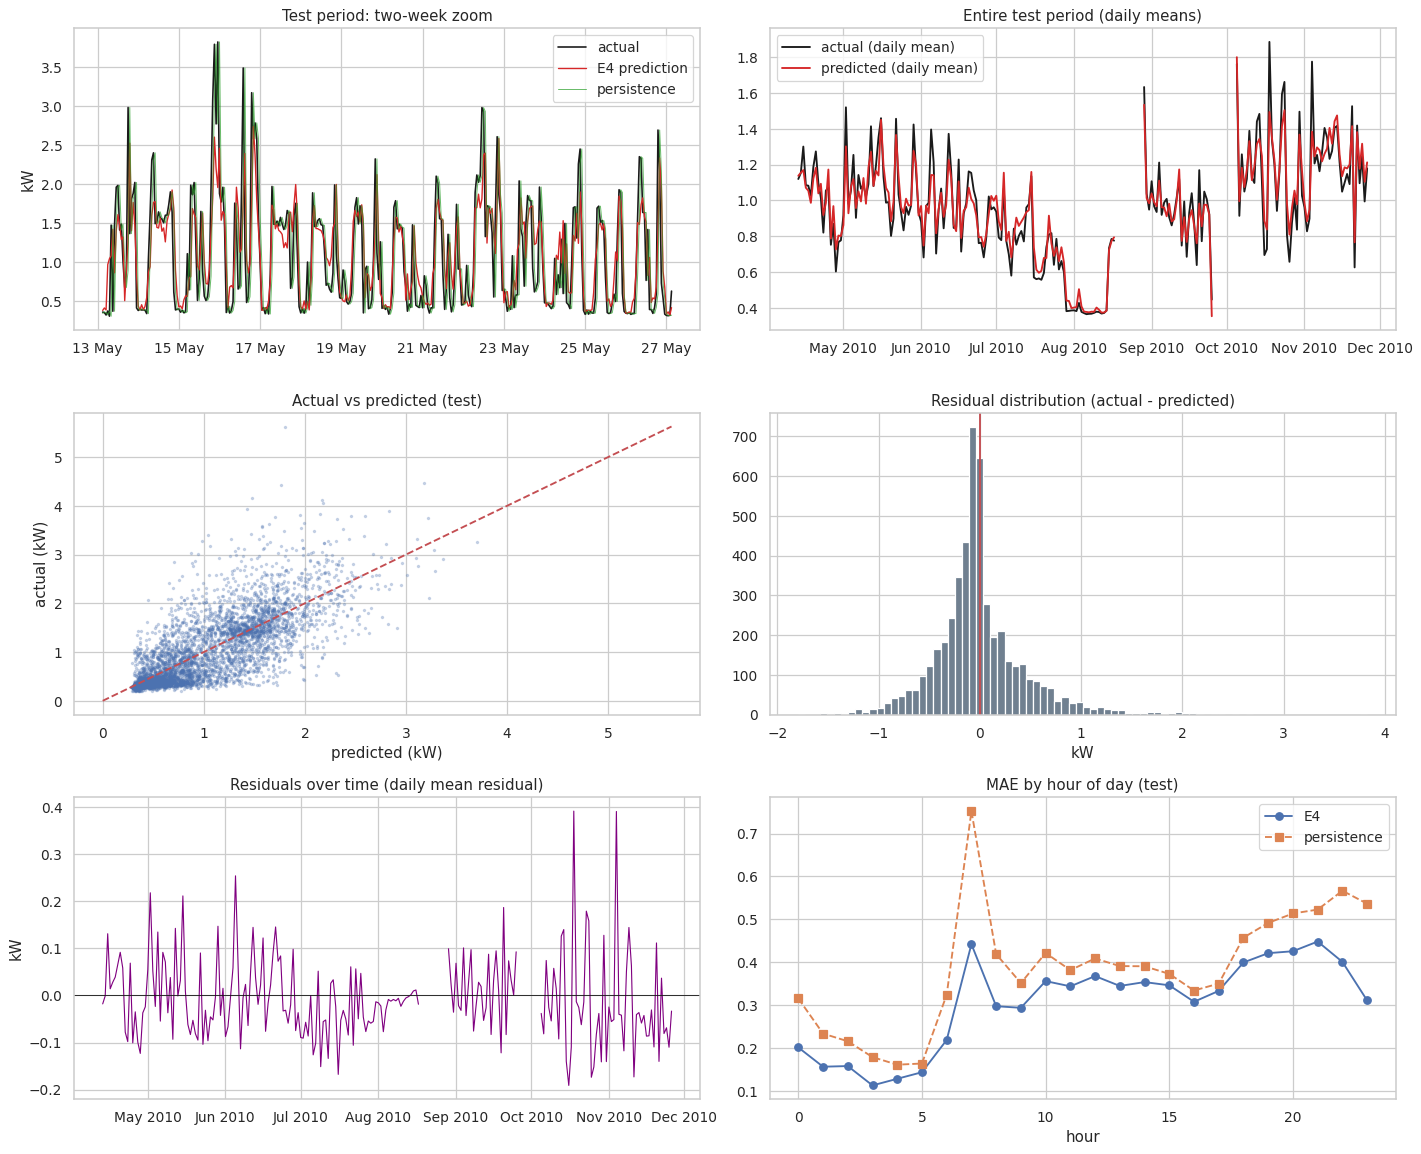

In [ ]:
best_est, best_feats = fitted_models[best_id]
pred_te = pd.Series(all_preds[best_id]["test"], index=yte.index, name="prediction"); base_te = pd.Series(all_preds["E0a"]["test"], index=yte.index)
res = yte - pred_te; res_base = yte - base_te
zoom = slice(yte.index[0] + pd.Timedelta(days=30), yte.index[0] + pd.Timedelta(days=44))
fig, ax = plt.subplots(3, 2, figsize=(16, 13))
ax[0, 0].plot(yte[zoom], color="k", lw=1.3, label="actual"); ax[0, 0].plot(pred_te[zoom], color="tab:red", lw=1.1, label=f"{best_id} prediction"); ax[0, 0].plot(base_te[zoom], color="tab:green", lw=.8, alpha=.7, label="persistence")
ax[0, 0].set_title("Test period: two-week zoom"); ax[0, 0].set_ylabel("kW"); ax[0, 0].legend(); ax[0, 0].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax[0, 1].plot(yte.resample("D").mean(), color="k", label="actual (daily mean)"); ax[0, 1].plot(pred_te.resample("D").mean(), color="tab:red", label="predicted (daily mean)")
ax[0, 1].set_title("Entire test period (daily means)"); ax[0, 1].legend(); ax[0, 1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax[1, 0].scatter(pred_te, yte, s=3, alpha=.25); lim = [0, max(yte.max(), pred_te.max())]; ax[1, 0].plot(lim, lim, "r--"); ax[1, 0].set_xlabel("predicted (kW)"); ax[1, 0].set_ylabel("actual (kW)"); ax[1, 0].set_title("Actual vs predicted (test)")
ax[1, 1].hist(res, bins=80, color="slategray"); ax[1, 1].axvline(0, c="r"); ax[1, 1].set_title("Residual distribution (actual - predicted)"); ax[1, 1].set_xlabel("kW")
ax[2, 0].plot(res.resample("D").mean(), color="purple", lw=.9); ax[2, 0].axhline(0, c="k", lw=.7); ax[2, 0].set_title("Residuals over time (daily mean residual)"); ax[2, 0].set_ylabel("kW"); ax[2, 0].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
hr = pd.DataFrame({"model": res.abs(), "persistence": res_base.abs()}).groupby(yte.index.hour).mean(); ax[2, 1].plot(hr["model"], "o-", label=best_id); ax[2, 1].plot(hr["persistence"], "s--", label="persistence"); ax[2, 1].set_title("MAE by hour of day (test)"); ax[2, 1].set_xlabel("hour"); ax[2, 1].legend()
fig.tight_layout(); save_fig(fig, "17_final_model_evaluation"); plt.show()

levels = pd.qcut(yte, 4, labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"])
lvl = pd.DataFrame({"actual_mean": yte.groupby(levels, observed=True).mean(), "MAE": res.abs().groupby(levels, observed=True).mean(), "bias(actual-pred)": res.groupby(levels, observed=True).mean(),
                    "persistence_MAE": res_base.abs().groupby(levels, observed=True).mean()})
display(lvl.round(3)); save_table(lvl.round(4), "final_error_by_consumption_level")
top = yte >= yte.quantile(0.95); skew_res = stats.skew(res)
summ = {"model": best_id, "bias_mean_residual": res.mean(), "residual_sd": res.std(), "share_overpredicted_%": (res < 0).mean() * 100, "top5pct_mean_residual": res[top].mean(), "top5pct_share_underpredicted_%": (res[top] > 0).mean() * 100,
        "worst_hour_of_day": int(hr["model"].idxmax()), "worst_hour_MAE": hr["model"].max(), "best_hour_of_day": int(hr["model"].idxmin()), "best_hour_MAE": hr["model"].min(), "residual_skew": skew_res}
display(pd.Series(summ, name="value").to_frame())
bt = exp.set_index("experiment").loc[best_id]

**Prediction plots**

In the two-week zoom (13 to 27 May 2010), the predictions of E4 follow the daily rhythm, with low overnight values and evening peaks. The highest peaks are underestimated; around 16 May, for example, the observed value is about 3.8 kW and the forecast is about 2.6 kW (values read from the plot). Persistence follows the observed series closely but, by construction, repeats each change one hour late. The daily-mean plot shows that the forecast follows the observed daily means over the test period, including the low-consumption stretch of about 0.4 kW in August 2010 (the data do not show the cause). Breaks in the lines correspond to periods without valid data. In the actual-against-predicted plot the points scatter widely around the 45° line, and predictions rarely exceed about 3.5 kW although some observed hours are above 5 kW. These visual impressions are quantified in the residual analysis below.

**Residual analysis**

The mean residual (actual − predicted) is −0.0074 kW, so the model has almost no average bias. It overpredicts in 61.5% of hours, but the larger errors are underpredictions: the residuals have a positive skew of 1.07 and a standard deviation of 0.447 kW. The underprediction is clearest at high loads. In the top 5% of observed hours (≥ 2.32 kW) the mean residual is +0.906 kW and 91.9% of the hours are underpredicted. The same pattern appears across consumption quartiles. MAE rises from 0.148 kW in the lowest quartile (mean 0.310 kW) to 0.491 kW in the highest (mean 1.969 kW), and the mean residuals are −0.147, −0.225, −0.033 and +0.374 kW, so low loads are overpredicted and high loads underpredicted. Because the quartiles are defined by the observed value, part of this pattern would appear for any imperfect forecast, but the size of the high-load underprediction shows that peaks are not well reproduced. Persistence has about the same MAE as the model in the lowest quartile (0.146 against 0.148 kW) and a larger MAE in the other three (0.300, 0.470 and 0.626 kW against 0.262, 0.317 and 0.491 kW).

By hour of day, the MAE of E4 is highest at 21:00 (0.448 kW) and lowest at 03:00 (0.113 kW). In the plot, 07:00 is almost as high (about 0.44 kW), and it is also where persistence has its largest error (about 0.75 kW). The MAE of the model is below that of persistence in every hour shown. Daily mean residuals range from −0.19 to +0.39 kW, and the larger positive values appear in October and November. The largest errors thus occur when load is rising in the morning, in the evening and at the highest loads; the notebook does not test why.

In [ ]:
final_pred_df = pd.DataFrame({"actual_kW": yte, "prediction_kW": pred_te, "persistence_kW": base_te, "residual_kW": res})
final_pred_df.round(5).to_csv(TABLE_DIR / "final_test_predictions.csv")
final_metrics = {"selected_experiment": best_id, "selection_criterion": "lowest validation MAE among trained models",
                 "validation": mdl.regression_metrics(yva, all_preds[best_id]["val"]), "test": mdl.regression_metrics(yte, all_preds[best_id]["test"]),
                 "test_persistence_baseline": mdl.regression_metrics(yte, all_preds["E0a"]["test"])}
json.dump(final_metrics, open(TABLE_DIR / "final_metrics.json", "w"), indent=2)
print(json.dumps(final_metrics, indent=1))

{
 "selected_experiment": "E4",
 "selection_criterion": "lowest validation MAE among trained models",
 "validation": {
  "MAE": 0.3502012637378169,
  "RMSE": 0.5163901855598914,
  "R2": 0.6644068937993775,
  "MAPE_pct": 36.32221348524974
 },
 "test": {
  "MAE": 0.30455558279944694,
  "RMSE": 0.44743354213076864,
  "R2": 0.600390240579987,
  "MAPE_pct": 39.19496551155733
 },
 "test_persistence_baseline": {
  "MAE": 0.38553550192527236,
  "RMSE": 0.5838668248149922,
  "R2": 0.31953372022552307,
  "MAPE_pct": 46.20829341251284
 }
}


**Final test performance**

The selected model (E4, tuned Random Forest) has a validation MAE of 0.3502 kW, RMSE of 0.5164 kW, R² of 0.664 and MAPE of 36.3%. On the test set its MAE is 0.3046 kW, RMSE 0.4474 kW, R² 0.600 and MAPE 39.2%. Persistence on the test set has MAE 0.3855 kW, RMSE 0.5839 kW, R² 0.320 and MAPE 46.2%. The model therefore reduces test MAE by 21.0% and RMSE by 23.4%, and R² almost doubles (0.600 against 0.320). MAE is lower on the test set than on the validation set, whereas R² and MAPE are worse (0.600 against 0.664, and 39.2% against 36.3%). This is consistent with the lower variance of the test target (standard deviation 0.708 kW against 0.891 kW in validation): absolute errors are smaller, but R² compares the squared error with that variance. The test MAE is about 32% of the mean test load (0.961 kW). These figures describe performance on one later period (April to November 2010) for one household. They do not show that the model generalises to other periods, seasons or households, and a single test split cannot quantify that uncertainty. The metrics were saved to `final_metrics.json` and the predictions to `final_test_predictions.csv`.

## 19. Conclusions and limitations

The results below bring together the main findings from data inspection, preprocessing, the six analytical questions, and forecasting experiments. The discussion also considers missing measurements, the use of hourly averages, the limited historical period, and how changes in household behavior could affect future forecasts.


In [ ]:
rk = exp.set_index("experiment")

**Data quality**

The file contains 2,075,259 one-minute rows from 16 December 2006 to 26 November 2010 on a complete, regular time grid, with no invalid or duplicate timestamps and no non-numeric entries. All seven measurements are missing together in 25,979 rows (1.25%). These form 71 runs; 7 of them are longer than four hours and account for 98.3% of the missing minutes, and the longest lasts 5.0 days.

**Preprocessing**

Minute readings were averaged to hourly values, and an hour was kept only if at least 45 minutes were observed (438 of 34,589 hours were invalid). Forward fill, limited to 3 hours and applied to model inputs only, bridges 30 target hours. Target values used for evaluation were never filled, and extreme values were retained. After rows without a target or complete inputs were removed, 32,807 supervised rows remained. The notebook did not test whether these choices change forecast accuracy.

**Exploration**

Consumption has a clear daily cycle (mean 0.44 kW at 04:00 and 1.90 kW at 20:00; hour of day accounts for 23.5% of hourly variance) and a weaker weekly pattern (weekday alone 1.1%; weekend mean 19.2% above the weekday mean). Monthly means range from 0.28 to 1.63 kW, but no long-term trend is detectable: the OLS slope is −0.015 kW per year (p = 0.708) and the slope adjusted for month-of-year effects is −0.005 kW per year. At the same hour, `Global_intensity` is almost perfectly correlated with active power (0.999) and `Voltage` is moderately and negatively correlated (−0.379). Previous-hour correlations are lower (0.714 for `Global_intensity`).

**Lags**

The autocorrelation of hourly active power is 0.72 at lag 1, 0.44 at lag 24 and 0.47 at lag 168. After shorter lags are accounted for, lag 1 remains dominant (partial autocorrelation 0.72) and lags 24 and 168 add small amounts (0.09 and 0.06). The recent hour and the same hour on previous days and weeks are therefore informative, which supports the lag features used in Section 12.

**Moving averages**

Longer windows smooth more (standard deviation relative to the hourly series falls from 0.87 for 3 hours to 0.36 for 168 hours) and respond later (best-aligned delays of 1 to 84 hours). Shifted so that they use earlier hours only, they are valid one-hour-ahead signals but weaker than the previous hour. On the common exploration hours, the 3-hour average has an MAE of 0.574 kW against 0.453 kW for persistence.

**Best experiment**

E4, the tuned Random Forest, was selected on validation MAE (0.3502 kW). On the test set it has MAE 0.3046 kW, RMSE 0.4474 kW and R² 0.600, which is a 21.0% lower MAE than persistence (0.3855 kW). Its test MAE is 13% lower than that of tuned Ridge (0.3511 kW). Tuning improved the forest's validation MAE by only 0.8% over the default settings, which is within the variation seen during cross-validation.

**Limitations**

1. The data come from one household between 2006 and 2010, and appliances, tariffs and behaviour have changed since then.
2. Hourly aggregation removes sub-hour peaks; the model forecasts average hourly load.
3. Imputation is minimal, but missing data removed 1,782 hourly rows, so predictions exist only where the history is complete.
4. Only a one-hour horizon was evaluated.
5. The test mean is 11.8% below the training mean, and a single test window limits any claim about generalisation.
6. The exploration window for Questions 4 to 6 overlaps the validation period, although not the test period.
7. The 45-minute hour threshold, the 3-hour fill limit and the small Random Forest search space were not tested against alternatives.
8. The features show predictive association and not causation.
9. Units are taken from the public dataset documentation.

Possible extensions are rolling-origin evaluation over several test windows, multi-step horizons, loss functions that emphasise peaks, gradient boosting, weather and holiday variables, and monitoring for drift.

## 20. Reproducibility and generated artifacts

The notebook saves the selected model, its configuration, evaluation results, figures, and supporting tables.

In [ ]:
meta = {"target": TARGET, "target_unit": "kW (hourly mean of minute-averaged active power; unit from public dataset documentation)", "frequency": "hourly", "horizon_hours": HORIZON,
        "selected_experiment": best_id, "model": rk.loc[best_id, "model"], "hyperparameters": rk.loc[best_id, "hyperparameters"], "features": best_feats,
        "training_period": [str(Xtr.index.min()), str(Xtr.index.max())], "validation_period": [str(Xva.index.min()), str(Xva.index.max())], "test_period": [str(Xte.index.min()), str(Xte.index.max())],
        "metrics": final_metrics, "preprocessing": {"min_observed_minutes_per_hour": MIN_OBS_PER_HOUR, "causal_fill_limit_hours": FILL_LIMIT_HOURS},
        "seed": SEED, "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__, "joblib": joblib.__version__}}
MODEL_PATH, META_PATH = MODEL_DIR / "best_model.joblib", MODEL_DIR / "best_model_metadata.json"
mdl.save_model_bundle(best_est, meta, MODEL_PATH, META_PATH)
reloaded = joblib.load(MODEL_PATH)
assert np.allclose(reloaded.predict(Xte[best_feats]), pred_te.to_numpy()), "reloaded model gives different predictions"
print("Model saved and reloaded: predictions identical; expected feature structure:", len(best_feats), "columns")
assert dl.sha256_of_file(RAW_PATH) == RAW_SHA256_BEFORE; print("Raw data checksum unchanged:", RAW_SHA256_BEFORE[:16], "...")

summary_md = f"""# Task 1 results summary (generated by the notebook)

* Data: {RAW_ROWS:,} minute rows, {minute.index.min()} to {minute.index.max()}; {(~valid_minutes).mean()*100:.2f}% rows with `?`.
* Modelling data: {n_hours:,} hourly rows ({n_valid:,} valid); supervised rows: {build_info['rows_kept']:,}.
* Split: train {split_tbl.n_rows[0]:,} / validation {split_tbl.n_rows[1]:,} / test {split_tbl.n_rows[2]:,} (chronological).
* Selected model (validation MAE): {best_id} - {rk.loc[best_id,'model']} ({rk.loc[best_id,'hyperparameters']}).
* Test: MAE {rk.loc[best_id,'Test_MAE']:.4f} kW, RMSE {rk.loc[best_id,'Test_RMSE']:.4f} kW, R2 {rk.loc[best_id,'Test_R2']:.4f}; persistence MAE {rk.loc['E0a','Test_MAE']:.4f} kW.

## Experiment table
{exp.round(4).to_markdown(index=False) if hasattr(exp, 'to_markdown') and __import__('importlib').util.find_spec('tabulate') else exp.round(4).to_string(index=False)}
"""
(REPORT_DIR / "results_summary.md").write_text(summary_md, encoding="utf-8")

artifacts = sorted(p.relative_to(PROJECT_ROOT).as_posix() for folder in (PROCESSED_DIR, FIG_DIR, TABLE_DIR, REPORT_DIR, MODEL_DIR) for p in folder.glob("*") if p.is_file())
display(pd.DataFrame({"artifact": artifacts, "size_KB": [round((PROJECT_ROOT / a).stat().st_size / 1024, 1) for a in artifacts]}))

Model saved and reloaded: predictions identical; expected feature structure: 31 columns
Raw data checksum unchanged: 4259c9d7ece5dbee ...


,artifact,size_KB
0,data/processed/hourly_inputs_causal_filled.csv,4372.6
1,data/processed/hourly_observed.csv,4167.0
2,outputs/figures/01_temporal_coverage.png,50.1
3,outputs/figures/02_missing_values.png,98.3
4,outputs/figures/03_histograms.png,112.2
5,outputs/figures/04_boxplots.png,89.3
6,outputs/figures/05_target_distribution.png,54.6
7,outputs/figures/06_correlation_heatmap_minute.png,134.0
8,outputs/figures/07_target_hourly_daily_weekly.png,308.9
9,outputs/figures/08_full_series_smoothed.png,251.0


**Interpretation**

The selected model was saved with its metadata, reloaded, and produced identical predictions on the test features (31 input columns), which confirms that the saved file reproduces the evaluated model. The SHA-256 checksum of the raw file at the end of the notebook (beginning 4259c9d7ece5dbee) matches the one recorded in Section 4, so the raw data were not changed. The artifact table lists 44 saved files: 2 processed hourly datasets, 17 figures, 22 tables and result files, the model and its metadata, and a results summary.